<div align="center">

# Trabajo Práctico: Predicción de Precios de Casas

**Aprendizaje Automático 1 — Tecnicatura en Inteligencia Artificial (FCEIA)**

</div>

---

**Integrantes:** 
* Aiup, Agustín.
* Paoloni, Franco.
* Silva, Julián.

---

## Librerias y Dataset

In [36]:
# Librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.linear_model import Lasso, Ridge
from sklearn.linear_model import ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from IPython.display import display

# Parámetros para las tablas.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Configuracion global de visualizacion
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.dpi': 100
})
sns.set_theme(style='whitegrid', palette='viridis')

# Semilla global.
RANDOM_STATE = 42

In [37]:
house_pricing = pd.read_csv(("../data/house-prices-tp.csv"))

## Análisis Exploratorio de Datos

En esta sección se elabora un diagnóstico general del conjunto de datos.

### Estructura General

In [38]:
print(f"Dimensiones del Dataset: {house_pricing.shape[0]} filas x {house_pricing.shape[1]} columnas.")

Dimensiones del Dataset: 556 filas x 14 columnas.


In [39]:
house_pricing.head(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.072,0.000,4.490,0.000,0.449,6.121,56.800,3.748,3.000,247.000,18.500,395.150,8.440,22.200
1,0.083,0.000,13.920,0.000,0.437,6.127,18.400,5.503,4.000,289.000,16.000,396.900,8.580,23.900
2,0.128,12.500,6.070,0.000,0.409,5.885,33.000,6.498,4.000,345.000,18.900,396.900,8.790,20.900
3,0.089,21.000,5.640,0.000,0.439,5.963,45.700,6.815,4.000,243.000,16.800,395.560,13.450,19.700
4,0.114,0.000,8.560,0.000,0.520,6.781,71.300,2.856,5.000,384.000,20.900,395.580,7.670,26.500
5,0.063,0.000,11.930,0.000,0.573,6.593,69.100,2.479,1.000,273.000,21.000,391.990,9.670,22.400
6,0.358,0.000,6.200,1.000,0.507,6.951,88.500,2.862,8.000,307.000,17.400,391.700,9.710,26.700
7,0.088,0.000,10.810,0.000,0.413,6.417,6.600,5.287,4.000,305.000,19.200,383.730,6.720,24.200
8,1.355,0.000,8.140,0.000,0.538,6.072,100.000,4.175,4.000,307.000,21.000,376.730,13.040,14.500
9,0.303,0.000,7.380,0.000,0.493,6.312,28.900,5.416,5.000,287.000,19.600,396.900,6.150,23.000


In [40]:
house_pricing.tail(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
546,0.664,20.000,3.970,0.000,0.647,7.333,100.000,1.895,5.000,264.000,13.000,383.290,7.790,36.000
547,0.028,75.000,2.950,0.000,0.428,6.595,21.800,5.401,3.000,252.000,18.300,395.630,4.320,30.800
548,0.575,0.000,6.200,0.000,0.507,8.337,73.300,3.838,8.000,307.000,17.400,385.910,2.470,41.700
549,0.323,0.000,21.890,0.000,0.624,5.942,93.500,1.967,4.000,437.000,21.200,378.250,16.900,17.400
550,0.087,45.000,3.440,0.000,0.437,7.178,26.300,6.480,5.000,398.000,15.200,390.490,2.870,36.400
551,0.082,30.000,4.930,0.000,0.428,6.481,18.500,6.190,6.000,300.000,16.600,379.410,6.360,23.700
552,0.475,0.000,9.900,0.000,0.544,6.113,58.800,4.002,4.000,304.000,18.400,396.230,12.730,21.000
553,0.250,0.000,21.890,0.000,0.624,5.857,98.200,1.669,4.000,437.000,21.200,392.040,21.320,13.300
554,32.504,6.529,8.937,1.000,NaN,4.017,NaN,5.244,20.417,197.237,19.639,6.267,7.034,23.029
555,0.239,0.000,9.690,0.000,0.585,6.019,65.300,2.409,6.000,391.000,19.200,396.900,12.920,21.200


In [41]:
house_pricing.info()

<class 'pandas.DataFrame'>
RangeIndex: 556 entries, 0 to 555
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     533 non-null    float64
 1   ZN       534 non-null    float64
 2   INDUS    541 non-null    float64
 3   CHAS     533 non-null    float64
 4   NOX      532 non-null    float64
 5   RM       535 non-null    float64
 6   AGE      532 non-null    float64
 7   DIS      541 non-null    float64
 8   RAD      528 non-null    float64
 9   TAX      538 non-null    float64
 10  PTRATIO  528 non-null    float64
 11  B        534 non-null    float64
 12  LSTAT    534 non-null    float64
 13  MEDV     535 non-null    float64
dtypes: float64(14)
memory usage: 60.9 KB


### Análisis Descriptivo

Se procede a tomar solamente las columnas en numéricas para analizarlas correctamente. Luego se analiza la variable categórica `CHAS` por su parte.

In [42]:
cols_numericas = house_pricing.drop(columns = ['CHAS'])

Estadísticos descriptivos para las variables numéricas.

In [43]:
desc = cols_numericas.describe().T
desc['mediana'] = cols_numericas.median()
desc['CV(%)'] = (desc['std'] / desc['mean']) * 100
desc['sesgo'] = cols_numericas.skew()
desc['curtosis'] = cols_numericas.kurtosis()


desc[['mean', 'mediana', 'std', 'CV(%)', 'min', '25%', '50%', '75%', 'max',
      'sesgo', 'curtosis']]

,mean,mediana,std,CV(%),min,25%,50%,75%,max,sesgo,curtosis
CRIM,5.846,0.315,13.829,236.568,0.006,0.084,0.315,4.871,88.976,3.747,15.249
ZN,13.197,0.000,24.903,188.699,0.000,0.000,0.000,20.000,100.000,1.958,2.750
INDUS,11.219,9.690,6.942,61.879,0.460,5.130,9.690,18.100,27.740,0.302,-1.206
NOX,0.560,0.538,0.119,21.332,0.385,0.453,0.538,0.644,0.871,0.694,-0.230
RM,6.292,6.208,0.782,12.435,3.561,5.876,6.208,6.639,8.780,0.374,1.555
AGE,67.632,76.500,28.462,42.083,2.900,42.275,76.500,93.825,100.000,-0.551,-1.038
DIS,3.944,3.340,2.256,57.191,1.130,2.112,3.340,5.401,12.127,1.079,0.705
RAD,9.699,5.000,8.684,89.537,1.000,4.000,5.000,23.633,24.000,0.951,-0.948
TAX,409.575,335.000,167.689,40.942,187.000,279.000,335.000,666.000,711.000,0.632,-1.171
PTRATIO,18.430,19.000,2.195,11.909,12.600,17.000,19.000,20.200,22.000,-0.787,-0.305


Se acompaña con histogramas y boxplots para analizar la distribución de las variables numéricas.

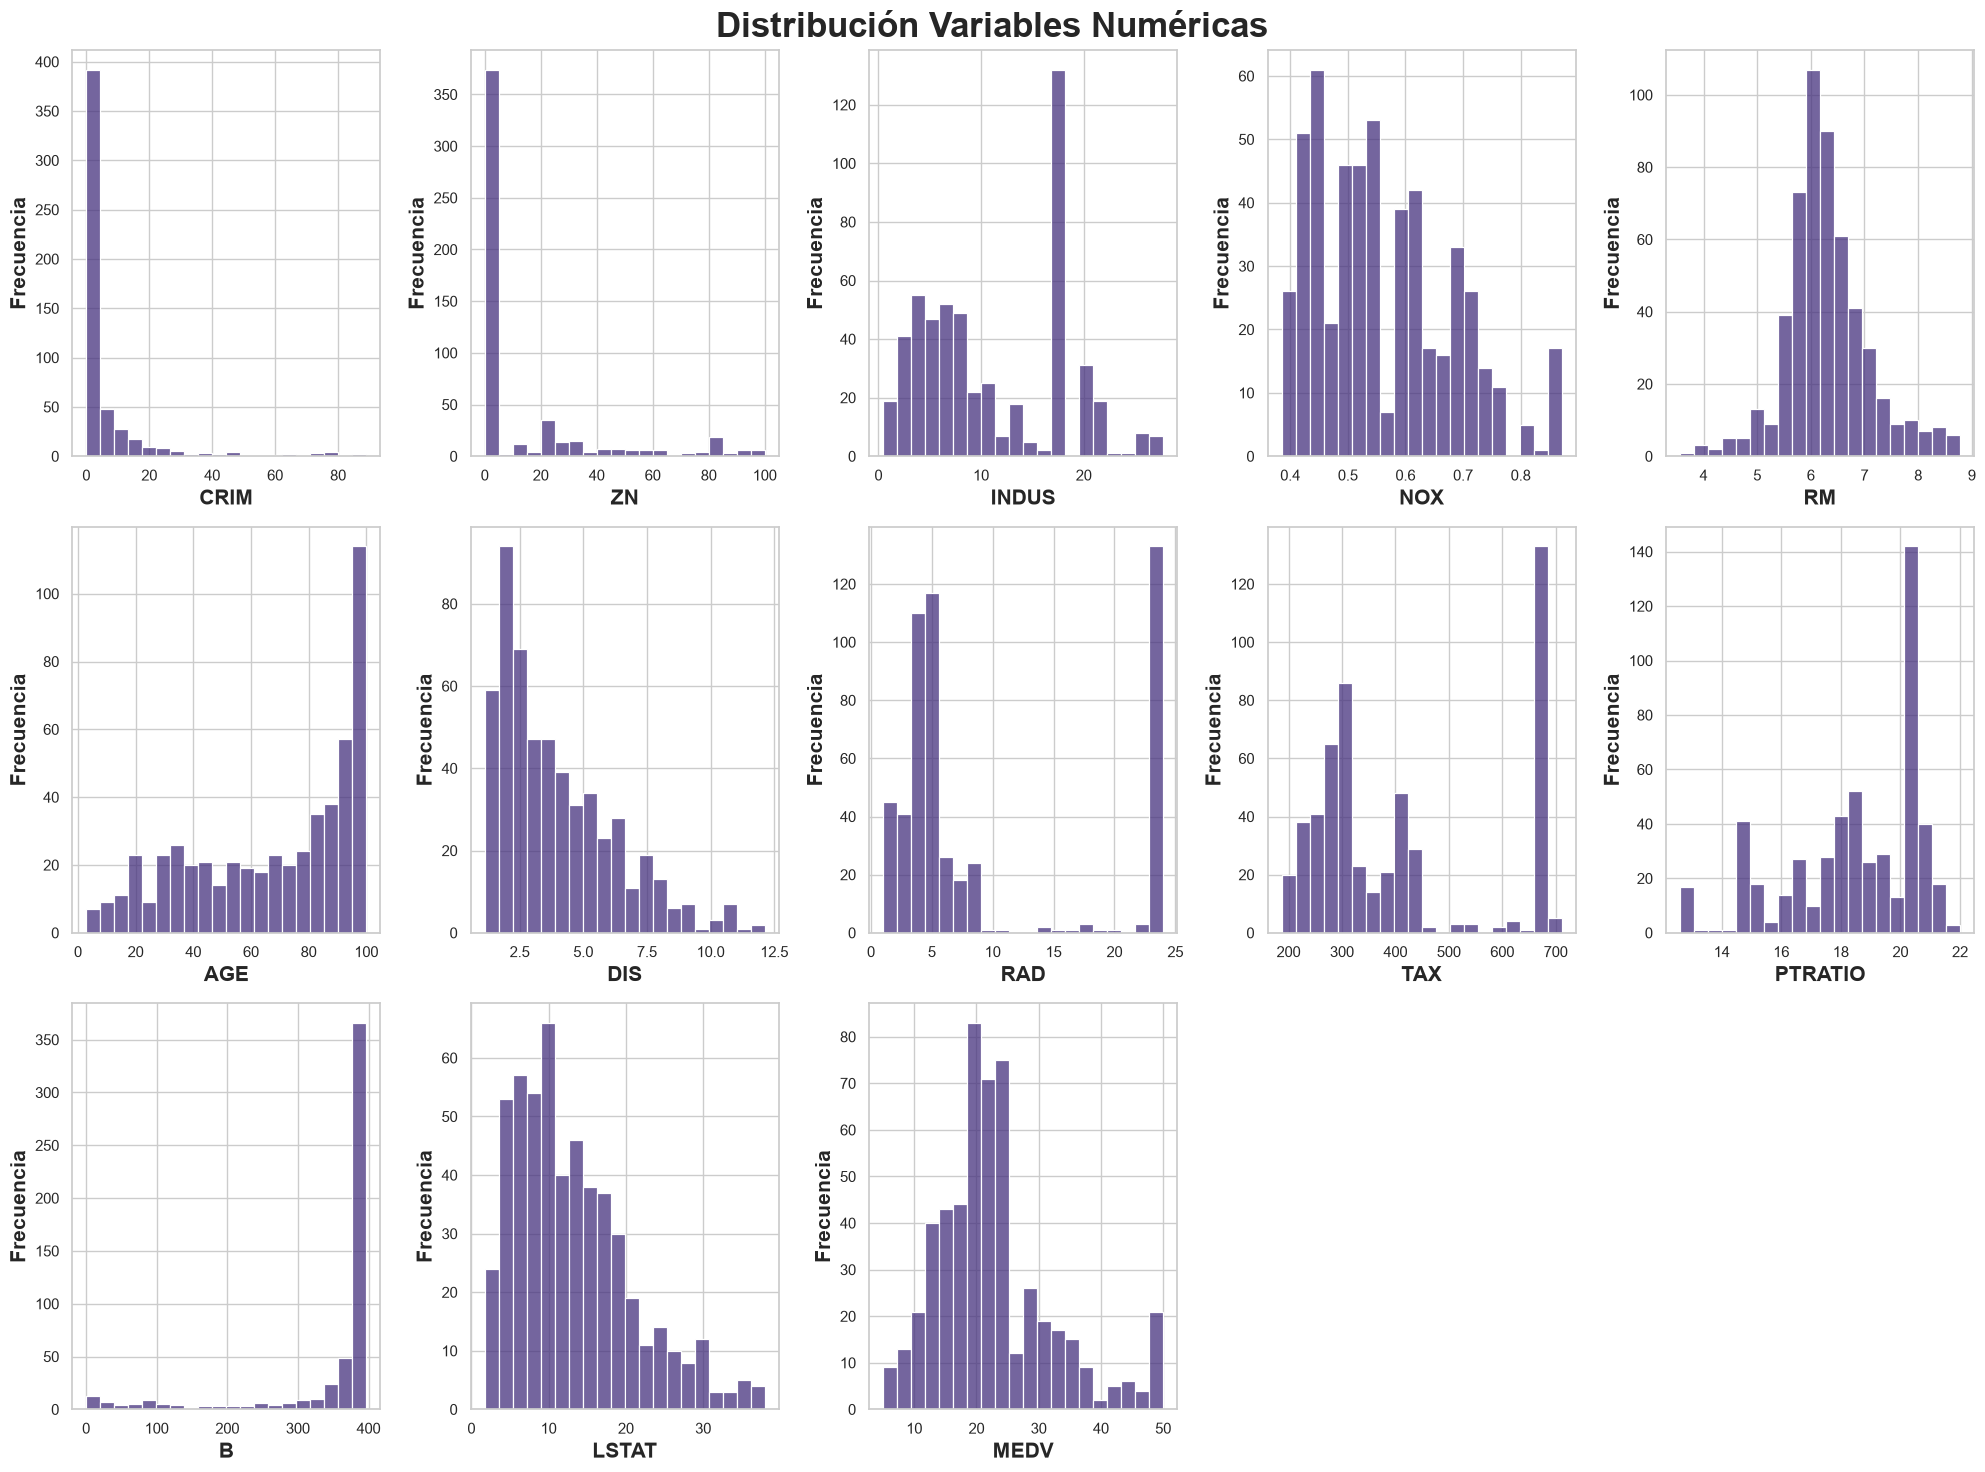

In [44]:
columnas_histograma = []

for columna in house_pricing.columns:
    if columna not in ['CHAS']:
        columnas_histograma.append(columna)


fig, axes = plt.subplots(ncols = 5, nrows = 3, figsize = (20, 15))
axes = axes.flatten()

for ax, columna in zip(axes, columnas_histograma):
    sns.histplot(house_pricing, x = columna, ax = ax, bins = 20)
    ax.set_ylabel('Frecuencia', fontweight = 'bold', fontsize = 15)
    ax.set_xlabel(columna, fontweight = 'bold', fontsize = 15)


for i in range(len(columnas_histograma), len(axes)):
    axes[i].set_visible(False)

plt.suptitle('Distribución Variables Numéricas', fontweight = 'bold', fontsize = 25)
plt.tight_layout()
plt.show()

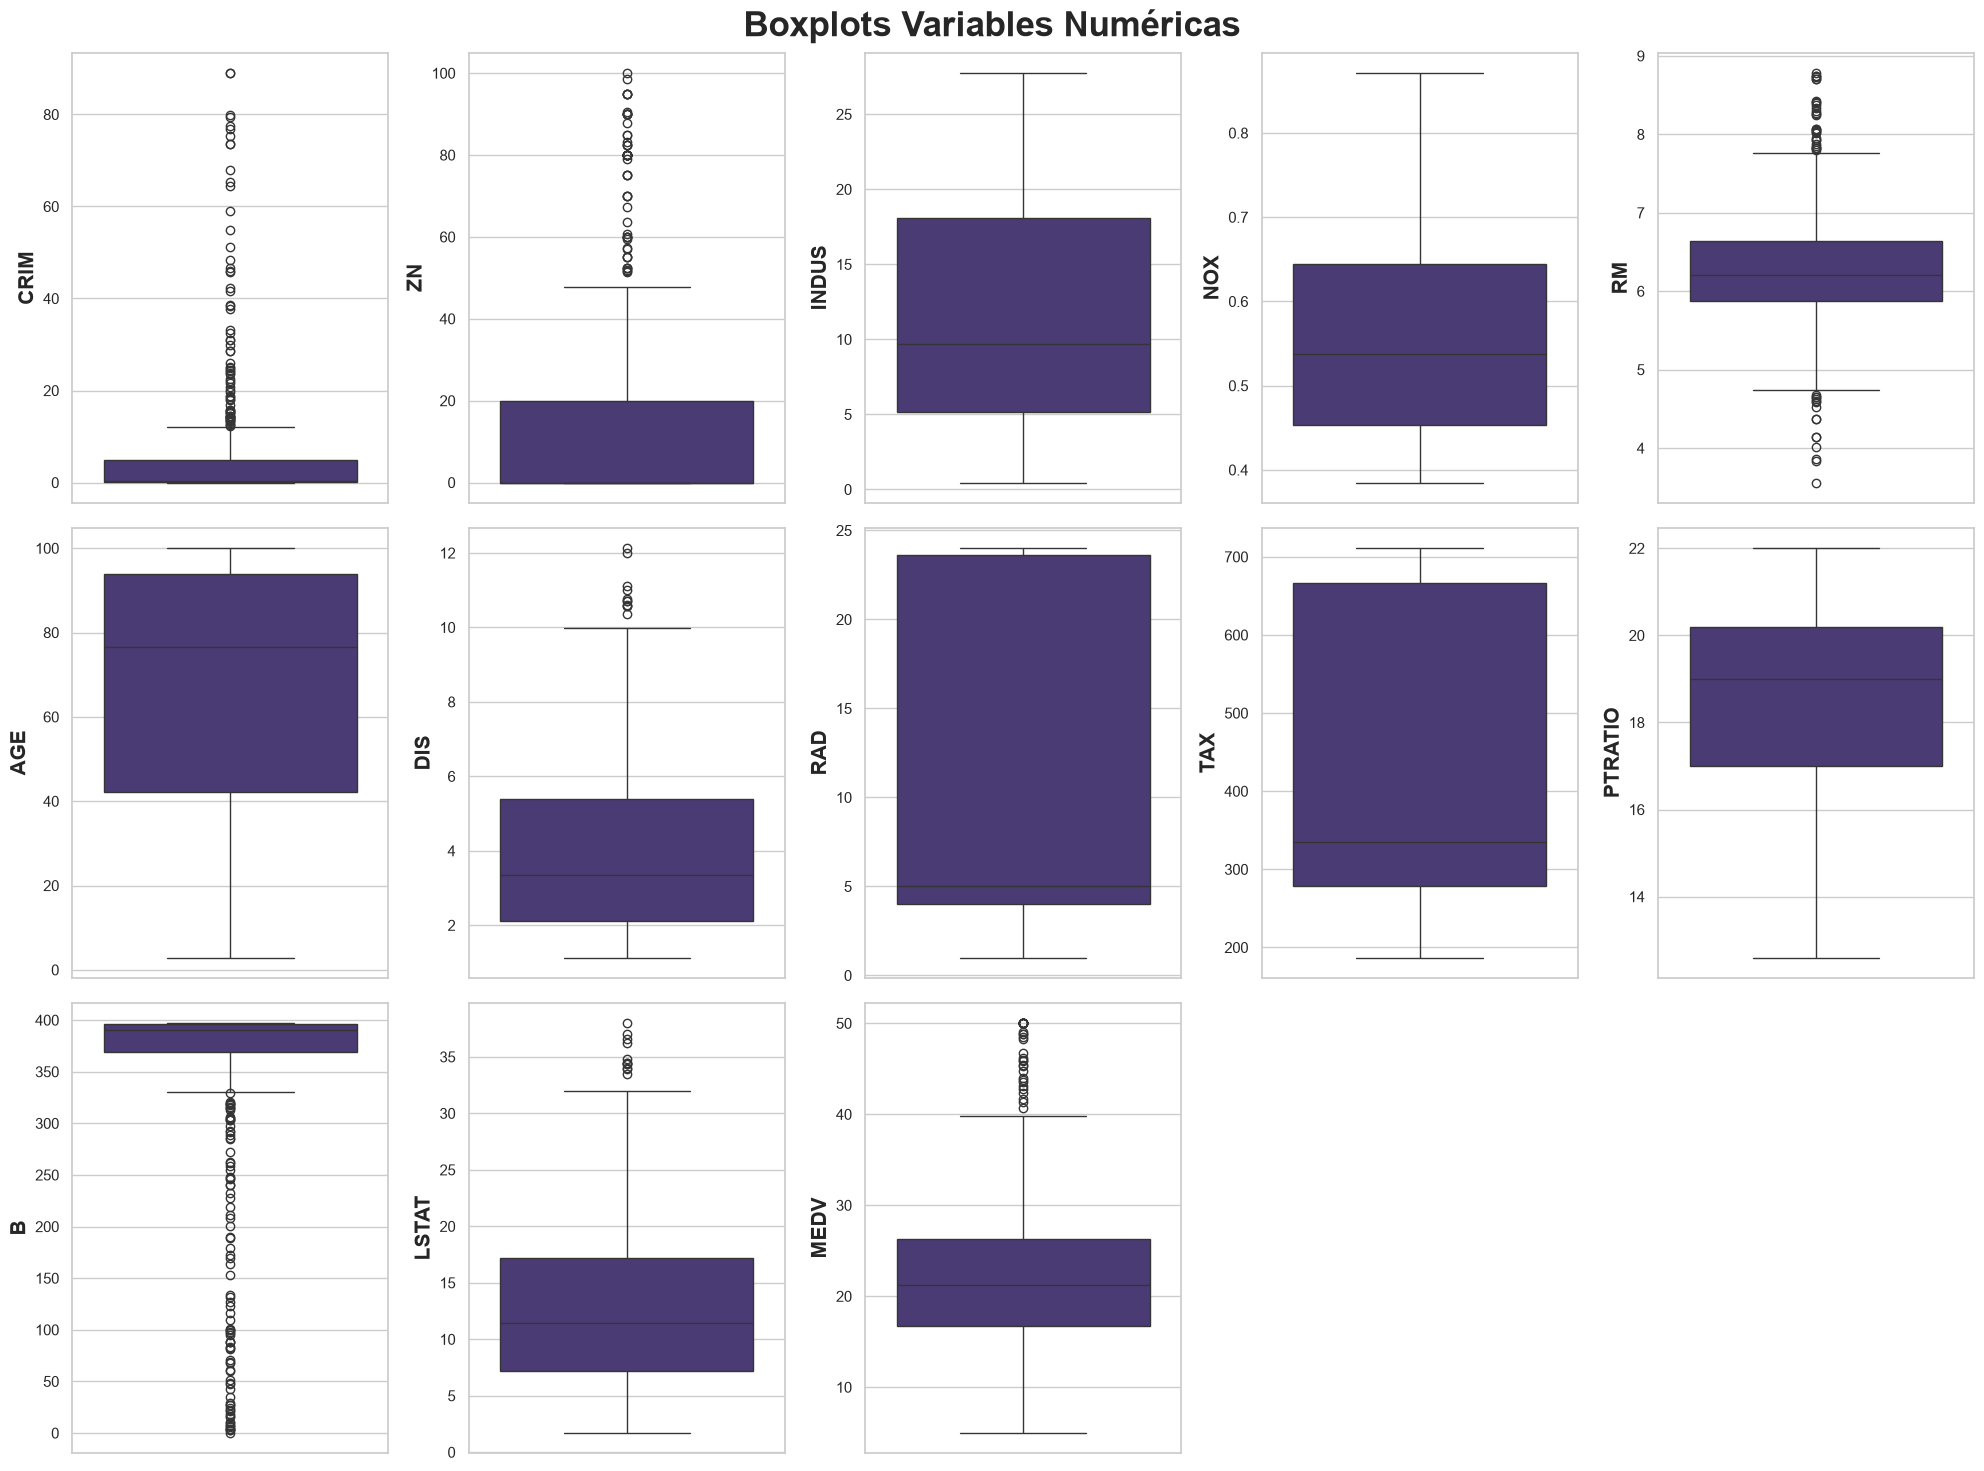

In [45]:
columnas_boxplot = []

for columna in house_pricing.columns:
    if columna != 'CHAS':
        columnas_boxplot.append(columna)

fig, axes = plt.subplots(ncols=5, nrows=3, figsize=(20, 15))
axes = axes.flatten()

for ax, columna in zip(axes, columnas_boxplot):
    sns.boxplot(data=house_pricing, y=columna, ax=ax)
    ax.set_ylabel(columna, fontweight = 'bold', fontsize = 15)

for i in range(len(columnas_boxplot), len(axes)):
    axes[i].set_visible(False)

fig.suptitle('Boxplots Variables Numéricas', fontweight = 'bold', fontsize = 25)
plt.tight_layout()
plt.show()

Por último, para la columna categórica `CHAS` se procede a graficar un countplot.

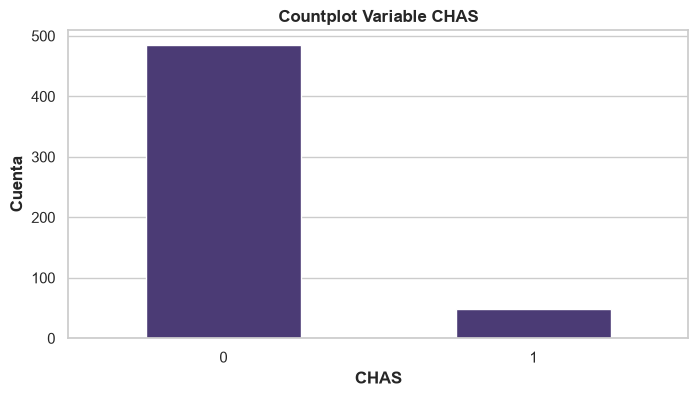

In [46]:
fig, ax = plt.subplots(figsize = (8, 4))

sns.countplot(house_pricing, x = 'CHAS', width = 0.5)
ax.set_title('Countplot Variable CHAS', fontweight = 'bold')
ax.set_xlabel('CHAS', fontweight = 'bold')
ax.set_xticks([0, 1])
ax.set_xticklabels(['0', '1'])
ax.set_ylabel('Cuenta', fontweight = 'bold')
plt.show()

### Análisis de Correlación

Se realiza un análisis de correlación para identificar qué predictoras se asocian con `MEDV` y detectar asociaciones fuertes entre predictoras.

Primero se realiza una matriz de correlacion de Pearson.

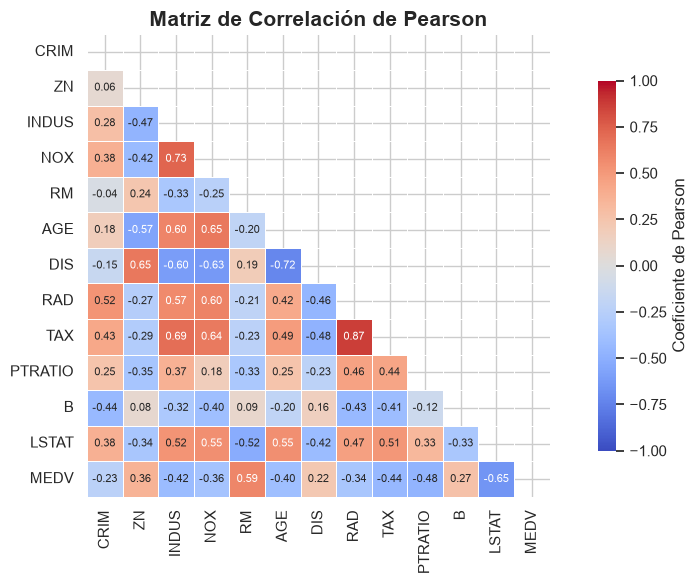

In [47]:
matriz_correlacion = cols_numericas.corr(method = 'pearson')

# Se enmascara el triángulo superior para no repetir cada coeficiente dos veces.
mascara = np.triu(np.ones_like(matriz_correlacion, dtype = bool))

fig, ax = plt.subplots(figsize = (10, 6))

sns.heatmap(matriz_correlacion, mask = mascara, annot = True, fmt = '.2f',
            annot_kws = {'size' : 8}, cmap = 'coolwarm', vmin = -1, vmax = 1,
            center = 0, square = True, linewidths = 0.5,
            cbar_kws = {'shrink' : 0.8, 'label' : 'Coeficiente de Pearson'}, ax = ax)

ax.set_title('Matriz de Correlación de Pearson', fontweight = 'bold', fontsize = 15)
plt.tight_layout()
plt.show()

Se procede a comparar con la correlación de Spearman, que en lugar de suponer linealidad de las variables, captura monotonía y al trabajar con rangos, es menos sensible a la magnitud de valores extremos, aunque no es inmune a ellos.

In [48]:
correlacion_pearson = house_pricing.corr(method = 'pearson')['MEDV'].drop(['MEDV', 'CHAS'])
correlacion_spearman = house_pricing.corr(method = 'spearman')['MEDV'].drop(['MEDV', 'CHAS'])

comparacion_correlaciones = pd.DataFrame({
    'pearson' : correlacion_pearson,
    'spearman' : correlacion_spearman
})

comparacion_correlaciones['diferencia'] = (comparacion_correlaciones['spearman'].abs() - comparacion_correlaciones['pearson'].abs())

orden_pearson = comparacion_correlaciones['pearson'].abs().sort_values(ascending = False).index
comparacion_correlaciones = comparacion_correlaciones.reindex(orden_pearson)

print(f"\n Correlación con MEDV (Pearson vs. Spearman): \n{comparacion_correlaciones}")


 Correlación con MEDV (Pearson vs. Spearman): 
         pearson  spearman  diferencia
LSTAT     -0.653    -0.802       0.150
RM         0.588     0.575      -0.013
PTRATIO   -0.475    -0.514       0.039
TAX       -0.438    -0.538       0.101
INDUS     -0.419    -0.516       0.098
AGE       -0.397    -0.547       0.151
ZN         0.362     0.443       0.081
NOX       -0.361    -0.509       0.148
RAD       -0.342    -0.326      -0.016
B          0.270     0.164      -0.106
CRIM      -0.228    -0.512       0.283
DIS        0.223     0.401       0.178


Se observa que a pesar de que los valores difieren, la relación (signos) de las correlaciones no varían.

### Análisis de Valores Faltantes

Se analiza la cantidad total de datos faltantes, por variable y por observación.

In [49]:
# Total de valores faltantes por variable (columnas):
total_nulos_variable = pd.DataFrame({
    'nulos_x_variable' : house_pricing.isna().sum(),
    'proporcion' : ((house_pricing.isna().sum() / len(house_pricing)) * 100)
    }).sort_values(by = 'proporcion', ascending = False)

total_nulos_variable = total_nulos_variable.reset_index()
total_nulos_variable = total_nulos_variable.rename(columns = {'index' : 'variable'})

# Total de valores faltantes por observación (filas):
total_nulos_filas = pd.DataFrame({
    'nulos_x_obs' : house_pricing.isna().sum(axis = 1)
    }).sort_values(by = 'nulos_x_obs', ascending = False)

total_nulos_filas = total_nulos_filas[total_nulos_filas['nulos_x_obs'] > 0]
total_nulos_filas = total_nulos_filas.reset_index()
total_nulos_filas = total_nulos_filas.rename(columns = {'index' : 'nro_fila'})


print(f"El dataset contiene {house_pricing.isna().sum().sum()} datos faltantes.")
print(f"\nTotal de valores faltantes (por variable): \n{total_nulos_variable}")
print(f"\nTotal de filas con datos faltantes: {len(total_nulos_filas)}")
print(f"\nFilas con datos faltantes: \n{total_nulos_filas}")

El dataset contiene 306 datos faltantes.

Total de valores faltantes (por variable): 
   variable  nulos_x_variable  proporcion
0   PTRATIO                28       5.036
1       RAD                28       5.036
2       NOX                24       4.317
3       AGE                24       4.317
4      CHAS                23       4.137
5      CRIM                23       4.137
6     LSTAT                22       3.957
7         B                22       3.957
8        ZN                22       3.957
9        RM                21       3.777
10     MEDV                21       3.777
11      TAX                18       3.237
12    INDUS                15       2.698
13      DIS                15       2.698

Total de filas con datos faltantes: 50

Filas con datos faltantes: 
    nro_fila  nulos_x_obs
0        187           14
1        267           13
2        406           13
3        317           13
4        430           12
5         61           12
6        528           11
7      

### Análisis de Outliers

Los boxplots de la sección de análisis descriptivo muestran valores alejados del cuerpo de cada distribución, utilizando el criterio del rango intercuartílico (IQR).

In [50]:
columnas_iqr = []
for columna in house_pricing.columns:
    if columna != 'CHAS':
        columnas_iqr.append(columna)

conteo_outliers = []

for columna in columnas_iqr:
    q1 = house_pricing[columna].quantile(0.25)
    q3 = house_pricing[columna].quantile(0.75)
    iqr = q3 - q1

    fuera_de_rango = (house_pricing[columna] < q1 - 1.5 * iqr) | (house_pricing[columna] > q3 + 1.5 * iqr)

    conteo_outliers.append({
        'variable' : columna,
        'outliers' : fuera_de_rango.sum(),
        'proporcion' : (fuera_de_rango.sum() / len(house_pricing)) * 100,
        'asimetria' : house_pricing[columna].skew()
    })

# Se ordena de mayor a menor cantidad de atípicos y se agrega la asimetría para interpretarlos.
outliers_iqr = pd.DataFrame(conteo_outliers).sort_values(by = 'outliers', ascending = False).reset_index(drop = True)

print(f"\n Outliers por variable (criterio IQR): \n{outliers_iqr}")


 Outliers por variable (criterio IQR): 
   variable  outliers  proporcion  asimetria
0         B        91      16.367     -2.398
1      CRIM        69      12.410      3.747
2        ZN        60      10.791      1.958
3        RM        45       8.094      0.374
4      MEDV        37       6.655      1.064
5     LSTAT        12       2.158      0.949
6       DIS        11       1.978      1.079
7       NOX         0       0.000      0.694
8     INDUS         0       0.000      0.302
9       TAX         0       0.000      0.632
10      RAD         0       0.000      0.951
11      AGE         0       0.000     -0.551
12  PTRATIO         0       0.000     -0.787


## Tratamiento de Datos

En la siguiente sección pasaremos a realizar el tratamiento de los datos faltantes y outliers.

### Tratamiento de Valores Faltantes

Como primer paso, se procede a eliminar los datos faltantes para la variable a predecir.

In [51]:
print(f"La variable MEDV tiene {house_pricing['MEDV'].isna().sum()} datos faltantes.")

house_pricing = house_pricing.dropna(subset = ['MEDV'])

print(f"\nEl DataFrame ahora tiene {len(house_pricing)} observaciones.")

La variable MEDV tiene 21 datos faltantes.

El DataFrame ahora tiene 535 observaciones.


Ahora se eliminan aquellas observaciones donde los valores faltantes son mayores a 3.

In [52]:
predictoras = house_pricing.drop(columns = 'MEDV').columns
nulos_por_fila = house_pricing[predictoras].isna().sum(axis = 1)

print(f"Se eliminan {len(house_pricing.loc[nulos_por_fila > 3])} observaciones con más de 3 faltantes.")
house_pricing = house_pricing.loc[nulos_por_fila <= 3]

house_pricing.info()

Se eliminan 12 observaciones con más de 3 faltantes.
<class 'pandas.DataFrame'>
Index: 523 entries, 0 to 555
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     519 non-null    float64
 1   ZN       519 non-null    float64
 2   INDUS    523 non-null    float64
 3   CHAS     522 non-null    float64
 4   NOX      521 non-null    float64
 5   RM       521 non-null    float64
 6   AGE      518 non-null    float64
 7   DIS      521 non-null    float64
 8   RAD      516 non-null    float64
 9   TAX      520 non-null    float64
 10  PTRATIO  519 non-null    float64
 11  B        521 non-null    float64
 12  LSTAT    521 non-null    float64
 13  MEDV     523 non-null    float64
dtypes: float64(14)
memory usage: 61.3 KB


### División Train - Test

Se procede a dividir el dataset en train y test, para evitar el _data leakage_ a la hora de imputar. Se reserva el 20%de las observaciones para prueba y se entrena con el 80% restante.

In [53]:
X = house_pricing.drop(columns = 'MEDV')
y = house_pricing['MEDV']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = RANDOM_STATE)

print(f"Entrenamiento: {X_train.shape[0]} filas y {X_train.shape[1]} predictoras")
print(f"Prueba: {X_test.shape[0]} filas y {X_test.shape[1]} predictoras")

Entrenamiento: 418 filas y 13 predictoras
Prueba: 105 filas y 13 predictoras


### Escalado de Variables

Previo a imputar, se procede al escalado de variables utilizando el método `RobustScaler`. Se elige este método porque se ve menos distorsionado por los _outliers_.

In [54]:
from sklearn.preprocessing import RobustScaler

escalador = RobustScaler()
X_train_escalado = escalador.fit_transform(X_train)
X_test_escalado = escalador.transform(X_test)

resumen_escalado = pd.DataFrame({
    'mediana_train': pd.DataFrame(X_train_escalado, columns=X_train.columns).median(),
    'rango_intercuartil_train': (
        pd.DataFrame(X_train_escalado, columns=X_train.columns).quantile(0.75)
        - pd.DataFrame(X_train_escalado, columns=X_train.columns).quantile(0.25)
    ),
    'mediana_test': pd.DataFrame(X_test_escalado, columns=X_test.columns).median(),
    'rango_intercuartil_test': (
        pd.DataFrame(X_test_escalado, columns=X_test.columns).quantile(0.75)
        - pd.DataFrame(X_test_escalado, columns=X_test.columns).quantile(0.25)
    )
}, index=X_train.columns)

print(f'\nMediana y rango intercuartílico después del escalado:\n{resumen_escalado}')


Mediana y rango intercuartílico después del escalado:
         mediana_train  rango_intercuartil_train  mediana_test  rango_intercuartil_test
CRIM             0.000                     1.000         0.048                    0.816
ZN               0.000                     1.000         0.000                    0.000
INDUS            0.000                     1.000         0.016                    0.948
CHAS             0.000                     0.000         0.000                    0.000
NOX              0.000                     1.000         0.085                    0.945
RM               0.000                     1.000        -0.114                    0.864
AGE             -0.000                     1.000         0.199                    0.848
DIS              0.000                     1.000        -0.170                    0.722
RAD              0.000                     1.000         0.000                    1.000
TAX              0.000                     1.000         0.036   

### Imputación Faltantes

Para imputar los datos faltantes se utiliza el método de _machine learning_ **KNN** para las variables numéricas, y para `CHAS` se utiliza su moda.

In [55]:
# Se separa CHAS de las predictoras
columnas_knn = X_train.columns.drop('CHAS')

# KNN: ajustar solo con train y transformar ambos conjuntos
imputador_knn = KNNImputer(n_neighbors=5, weights='distance')

X_train_knn = imputador_knn.fit_transform(X_train_escalado[:, X_train.columns.get_indexer(columnas_knn)])
X_test_knn = imputador_knn.transform(X_test_escalado[:, X_test.columns.get_indexer(columnas_knn)])

# Moda de CHAS calculada solo con train
imputador_chas = SimpleImputer(strategy='most_frequent')
chas_indice = X_train.columns.get_loc('CHAS')

X_train_chas = imputador_chas.fit_transform(X_train_escalado[:, [chas_indice]])
X_test_chas = imputador_chas.transform(X_test_escalado[:, [chas_indice]])

# Reconstruir matrices manteniendo el orden original de las columnas
X_train_escalado[:, chas_indice] = X_train_chas.ravel()
X_test_escalado[:, chas_indice] = X_test_chas.ravel()

indices_knn = X_train.columns.get_indexer(columnas_knn)
X_train_escalado[:, indices_knn] = X_train_knn
X_test_escalado[:, indices_knn] = X_test_knn


print('Nulos en X_train_escalado:', np.isnan(X_train_escalado).sum())
print('Nulos en X_test_escalado:', np.isnan(X_test_escalado).sum())

Nulos en X_train_escalado: 0
Nulos en X_test_escalado: 0


### Tratamiento de Outliers

Se decidió conservar los valores identificados como atípicos por el criterio del rango intercuartílico (IQR) en el boxplot. Este criterio señala observaciones alejadas de la distribución central, pero eso no significa que sean errores: en este conjunto, algunas representan características plausibles de los barrios. Por ejemplo, `CRIM` tiene una cola hacia valores altos, que refleja diferencias reales entre zonas; eliminarlos reduciría la diversidad que el modelo debe aprender. En `ZN` y `B`, la forma asimétrica de las distribuciones también puede hacer que el IQR marque valores válidos como atípicos.

Además, `MEDV` tiene un límite superior de 50,0. Las observaciones en ese valor corresponden al tope de la variable y no deben descartarse solo por aparecer en el extremo de la distribución. En conjunto, eliminar todos los valores marcados podría quitar información relevante y sesgar la muestra. Por eso se conservan y se consideran al interpretar el modelo.

### Codificación de Variables Categóricas

En este dataset las 13 predictoras ya son numéricas, por lo que no hay que codificar variables categóricas.

## Regresión Lineal Múltiple

Se ajusta el primer modelo sobre las 13 predictoras escaladas. Servirá como referencia para comparar los modelos que se incorporen después.

Se calculan tres métricas para el conjunto de entrenamiento y el de prueba:

- **R²**: proporción de la variabilidad de `MEDV` que el modelo logra explicar.
- **RMSE** (raíz del error cuadrático medio): el error típico, expresado en miles de dólares.
- **MAE** (error absoluto medio): el promedio de los errores en valor absoluto, también en miles de dólares.

In [56]:
# Función auxiliar para calcular métricas.
def calcular_metricas(y_real, y_predicho):
    return {
        'R2' : r2_score(y_real, y_predicho),
        'RMSE' : np.sqrt(mean_squared_error(y_real, y_predicho)),
        'MAE' : mean_absolute_error(y_real, y_predicho)
    }

In [57]:
regresion_lineal = LinearRegression()
regresion_lineal.fit(X_train_escalado, y_train)

y_pred_train = regresion_lineal.predict(X_train_escalado)
y_pred_test = regresion_lineal.predict(X_test_escalado)

# Coeficientes del modelo lineal.
coeficientes_lineal = pd.DataFrame({'coeficiente' : regresion_lineal.coef_}, index = X_train.columns)

# Se ordena por magnitud para identificar las variables con mayor peso en la predicción.
orden_coeficientes = coeficientes_lineal['coeficiente'].abs().sort_values(ascending = False).index
coeficientes_lineal = coeficientes_lineal.reindex(orden_coeficientes)

print(f"Intercepto: {regresion_lineal.intercept_:.3f}")
print(f"\n Coeficientes del modelo: \n{coeficientes_lineal}")

# Métricas para la regresión lineal.
metricas_lineal = pd.DataFrame({
    'train' : calcular_metricas(y_train, y_pred_train),
    'test' : calcular_metricas(y_test, y_pred_test)
})

print(f"\n Regresión lineal múltiple: \n{metricas_lineal}")

Intercepto: 22.162

 Coeficientes del modelo: 
         coeficiente
TAX           -7.044
CHAS           6.400
RAD            5.030
LSTAT         -4.763
DIS           -4.436
RM             2.558
NOX           -2.453
PTRATIO       -2.250
AGE           -1.395
ZN             1.317
INDUS          1.191
CRIM           0.341
B              0.145

 Regresión lineal múltiple: 
      train  test
R2    0.668 0.647
RMSE  5.325 5.798
MAE   3.654 3.864


## Regresión Lineal con Descenso por el Gradiente

En lugar de resolver los coeficientes mínimos cuadrados (OLS), el modelo se ajusta de manera iterativa mediante **descenso por el gradiente**.

Se utilizan tres variantes:

* Gradiente Descendiente. 
* Gradiente Descendiente Estocástico.
* Gradiente Descendiente _mini_batch_.

Las tres minimizan la misma función de costo (el Error Cuadrático Medio) y devuelven el vector de pesos $W$, con el término independiente en la primera posición. 

Comparar sus resultados con los de OLS permite verificar empíricamente si la aproximación iterativa alcanza la misma solución que el método analítico.

#### Funciones

In [58]:
def gradient_descent(X_train, y_train, X_val, y_val, lr=0.01, epochs=100):
    """
    Entrena un modelo de regresión lineal mediante Gradient Descent.
    La función ajusta los pesos W de un modelo lineal de la forma:
        y_pred = X @ W

    utilizando el Error Cuadrático Medio (MSE) como función de costo.

    Parámetros
    ----------
    X_train :
      np.ndarray Matriz de características de entrenamiento de dimensiones (n, m), donde n es la cantidad de muestras y m la cantidad de variables.
    y_train :
      np.ndarray Vector de valores objetivo de entrenamiento de dimensiones (n, 1).
    X_val :
      np.ndarray Matriz de características de validación de dimensiones (p, m), donde p es la cantidad de muestras de validación.
    y_val :
      np.ndarray Vector de valores objetivo de validación de dimensiones (p, 1).
    lr :
      float, optional Tasa de aprendizaje utilizada para actualizar los pesos. Por defecto es 0.01.
    epochs :
      int, optional Cantidad de iteraciones del algoritmo de Gradient Descent. Por defecto es 100.

    Retorna
    -------
    np.ndarray Vector de pesos W de dimensiones (m + 1, 1), incluyendo el término independiente (bias).

    Proceso
    -------
    1. Se agrega una columna de unos a X_train y X_val para representar el término independiente (bias).
    2. Se inicializan aleatoriamente los pesos W.
    3. En cada época:
      - Se calcula la predicción sobre el conjunto de entrenamiento.
      - Se calcula el MSE de entrenamiento.
      - Se calcula la predicción sobre el conjunto de validación.
      - Se calcula el MSE de validación.
      - Se calcula el gradiente de la función de costo respecto de W.
      - Se actualizan los pesos utilizando la regla de Gradient Descent: W = W - lr * gradient
      4. Finalmente, se grafica la evolución del MSE de entrenamiento y validación a lo largo de las épocas.
        El gradiente utilizado corresponde a: ∇J(W) = -(2 / n) X.T (y - XW) donde J(W) es el Error Cuadrático Medio.
    """
    n = X_train.shape[0]
    m = X_train.shape[1]

    o = X_val.shape[0]

    # Poner columna de unos a las matrices X
    X_train = np.hstack((np.ones((n, 1)), X_train))
    X_val = np.hstack((np.ones((o, 1)), X_val))


    # Inicializar pesos aleatorios
    W = np.random.randn(m+1).reshape(m+1, 1)

    train_errors = []  # Para almacenar el error de entrenamiento en cada época
    test_errors = []   # Para almacenar el error de prueba en cada época

    for _ in range(epochs):
        # Calcular predicción y error de entrenamiento
        prediction_train = np.matmul(X_train, W)
        error_train = y_train - prediction_train
        #print(error_train)
        train_mse = np.mean(error_train ** 2)
        train_errors.append(train_mse)

        # Calcular predicción y error de prueba
        prediction_test = np.matmul(X_val, W)
        error_test = y_val - prediction_test
        test_mse = np.mean(error_test ** 2)
        test_errors.append(test_mse)

        # Calcular el gradiente y actualizar pesos
        grad_sum = np.sum(error_train * X_train, axis=0)
        grad_mul = -2/n * grad_sum  # 1xm
        gradient = np.transpose(grad_mul).reshape(-1, 1)  # mx1

        W = W - (lr * gradient)

    # Graficar errores de entrenamiento y prueba
    # Definir una figura
    plt.figure(figsize=(12, 6))
    # Plotear errores de entrenamiento
    plt.plot(train_errors, label='Error de entrenamiento')
    # Plotear errores de prueba
    plt.plot(test_errors, label='Error de validación')
    # Poner labels en los ejes
    plt.xlabel('Época')
    plt.ylabel('Error cuadrático medio')
    # Activar la leyenda
    plt.legend()
    # Poner titulo
    plt.title('Error de entrenamiento y validación vs iteraciones (GD)')
    # Terminar y mostrar gráfico
    plt.show()

    return W


def stochastic_gradient_descent(X_train, y_train, X_test, y_test, lr=0.01, epochs=100):
    """
    Entrena un modelo de regresión lineal mediante Stochastic Gradient Descent (SGD).

    La función ajusta los pesos W de un modelo lineal de la forma:

        y_pred = X @ W

    utilizando el Error Cuadrático Medio (MSE) como función de costo.

    A diferencia de Gradient Descent tradicional, que calcula el gradiente
    utilizando todas las muestras antes de actualizar los pesos, SGD actualiza
    los pesos después de procesar cada muestra individual.

    Parámetros
    ----------
    X_train : np.ndarray
        Matriz de características de entrenamiento de dimensiones (n, m),
        donde n es la cantidad de muestras y m la cantidad de variables.

    y_train : np.ndarray
        Vector de valores objetivo de entrenamiento de dimensiones (n, 1).

    X_test : np.ndarray
        Matriz de características de prueba de dimensiones (p, m).

    y_test : np.ndarray
        Vector de valores objetivo de prueba de dimensiones (p, 1).

    lr : float, optional
        Tasa de aprendizaje utilizada para actualizar los pesos.
        Por defecto es 0.01.

    epochs : int, optional
        Cantidad de épocas de entrenamiento. En cada época se recorren
        todas las muestras de entrenamiento. Por defecto es 100.

    Retorna
    -------
    np.ndarray
        Vector de pesos W de dimensiones (m + 1, 1), incluyendo el
        término independiente (bias).

    Proceso
    -------
    1. Se agrega una columna de unos a X_train y X_test para incorporar
      el término independiente (bias).

    2. Se inicializan aleatoriamente los pesos W.

    3. En cada época se permutan aleatoriamente las muestras de entrenamiento
      para evitar que el orden de los datos afecte al proceso de aprendizaje.

    4. Para cada muestra de entrenamiento:
      - Se calcula la predicción.
      - Se calcula el error entre el valor real y la predicción.
      - Se calcula el error cuadrático de esa muestra.
      - Se calcula el gradiente respecto de los pesos.
      - Se actualizan inmediatamente los pesos.

    5. Después de cada actualización se calcula el MSE sobre el conjunto
      de prueba para observar la evolución del modelo.

    El gradiente utilizado para una muestra individual es:

        ∇J(W) = -2 * x_i.T * (y_i - x_i @ W)

    y la actualización de los pesos es:

        W = W - lr * ∇J(W)

    La principal diferencia respecto de Gradient Descent tradicional es que
    el gradiente se calcula y los pesos se actualizan utilizando una sola
    muestra por vez, en lugar de utilizar todo el conjunto de entrenamiento.
    """
    n = X_train.shape[0]
    m = X_train.shape[1]

    X_train = np.hstack((np.ones((n, 1)), X_train))
    X_test = np.hstack((np.ones((X_test.shape[0], 1)), X_test))

    W = np.random.randn(m + 1).reshape(-1, 1)

    train_errors = []
    test_errors = []

    for i in range(epochs):
        # Permutación aleatoria de los datos
        permutation = np.random.permutation(n)
        X_train = X_train[permutation]
        y_train = y_train[permutation]

        for j in range(n):
            # Obtener una muestra aleatoria de un solo dato para hacer SGD
            x_sample = X_train[j]
            y_sample = y_train[j][0]

            prediction = np.matmul(x_sample, W)
            error = y_sample - prediction
            train_mse = error ** 2
            train_errors.append(train_mse)

            prediction_test = np.matmul(X_test, W)
            error_test = y_test - prediction_test
            test_mse = np.mean(error_test ** 2)
            test_errors.append(test_mse)

            gradient = -2 * error * x_sample.T.reshape(-1, 1)

            W = W - (lr * gradient)


    plt.figure(figsize=(12, 6))
    plt.plot(train_errors, label='Error de entrenamiento')
    plt.plot(test_errors, label='Error de prueba')
    plt.xlabel('Iteración')
    plt.ylabel('Error cuadrático medio')
    plt.legend()
    plt.title('Error de entrenamiento y prueba vs iteraciones (SGD)')
    plt.show()

    return W


def mini_batch_gradient_descent(X_train, y_train, X_test, y_test, lr=0.01, epochs=100, batch_size=11):
    """
    Entrena un modelo de regresión lineal mediante Mini-Batch Gradient Descent.

    La función ajusta los pesos W de un modelo lineal de la forma:

        y_pred = X @ W

    utilizando el Error Cuadrático Medio (MSE) como función de costo.

    Mini-Batch Gradient Descent combina las características de Gradient Descent
    tradicional y Stochastic Gradient Descent (SGD): en lugar de calcular el
    gradiente utilizando todo el conjunto de entrenamiento o una única muestra,
    calcula el gradiente utilizando pequeños lotes (mini-batches) de datos.

    Parámetros
    ----------
    X_train : np.ndarray
        Matriz de características de entrenamiento de dimensiones (n, m),
        donde n es la cantidad de muestras y m la cantidad de variables.

    y_train : np.ndarray
        Vector de valores objetivo de entrenamiento de dimensiones (n, 1).

    X_test : np.ndarray
        Matriz de características de prueba de dimensiones (p, m).

    y_test : np.ndarray
        Vector de valores objetivo de prueba de dimensiones (p, 1).

    lr : float, optional
        Tasa de aprendizaje utilizada para actualizar los pesos.
        Por defecto es 0.01.

    epochs : int, optional
        Cantidad de épocas de entrenamiento. En cada época se recorren
        todos los mini-batches del conjunto de entrenamiento.
        Por defecto es 100.

    batch_size : int, optional
        Cantidad de muestras utilizadas para calcular cada actualización
        de los pesos. Por defecto es 11.

    Retorna
    -------
    np.ndarray
        Vector de pesos W de dimensiones (m + 1, 1), incluyendo el
        término independiente (bias).

    Proceso
    -------
    1. Se agrega una columna de unos a X_train y X_test para incorporar
      el término independiente (bias).

    2. Se inicializan aleatoriamente los pesos W.

    3. En cada época se realiza una permutación aleatoria de las muestras
      de entrenamiento para evitar que el orden de los datos influya
      sistemáticamente en el aprendizaje.

    4. El conjunto de entrenamiento se divide en mini-batches de tamaño
      batch_size.

    5. Para cada mini-batch:
      - Se calcula la predicción:

            y_pred = X_batch @ W

      - Se calcula el error:

            error = y_batch - y_pred

      - Se calcula el MSE del mini-batch.
      - Se calcula el gradiente utilizando todas las muestras del
        mini-batch.
      - Se actualizan inmediatamente los pesos.

    6. Después de cada actualización se calcula el MSE sobre el conjunto
      de prueba para evaluar la evolución del modelo.

    El gradiente utilizado es:

        ∇J(W) = -(2 / batch_size) * X_batch.T @ (y_batch - X_batch @ W)

    y la actualización de los pesos es:

        W = W - lr * ∇J(W)

    La principal diferencia respecto de los otros métodos es el tamaño
    del conjunto utilizado para cada actualización:

        Gradient Descent:
            utiliza todas las muestras.

        Stochastic Gradient Descent:
            utiliza una única muestra.

        Mini-Batch Gradient Descent:
            utiliza un pequeño grupo de muestras.

    Por lo tanto, Mini-Batch Gradient Descent busca un equilibrio entre
    la estabilidad del gradiente calculado sobre todo el dataset y la
    velocidad y frecuencia de actualización característica de SGD.
    """
    n = X_train.shape[0]
    m = X_train.shape[1]

    X_train = np.hstack((np.ones((n, 1)), X_train))
    X_test = np.hstack((np.ones((X_test.shape[0], 1)), X_test))

    W = np.random.randn(m + 1).reshape(-1, 1)

    train_errors = []
    test_errors = []

    for i in range(epochs):

        # Permutación aleatoria de los datos
        permutation = np.random.permutation(n)
        X_train = X_train[permutation]
        y_train = y_train[permutation]


        for j in range(0, n, batch_size):
            # Obtener un lote (mini-batch) de datos
            x_batch = X_train[j:j+batch_size, :]
            y_batch = y_train[j:j+batch_size].reshape(-1, 1)

            prediction = np.matmul(x_batch, W)
            error = y_batch - prediction
            train_mse = np.mean(error ** 2)
            train_errors.append(train_mse)

            gradient = -2 * np.matmul(x_batch.T, error) / batch_size

            W = W - (lr * gradient)

            prediction_test = np.matmul(X_test, W)
            error_test = y_test - prediction_test
            test_mse = np.mean(error_test ** 2)
            test_errors.append(test_mse)

    plt.figure(figsize=(12, 6))
    plt.plot(train_errors, label='Error de entrenamiento')
    plt.plot(test_errors, label='Error de prueba')
    plt.xlabel('Iteración')
    plt.ylabel('Error cuadrático medio')
    plt.legend()
    plt.title('Error de entrenamiento y prueba vs iteraciones (Mini-Batch GD)')
    plt.show()

    return W

### Implementación

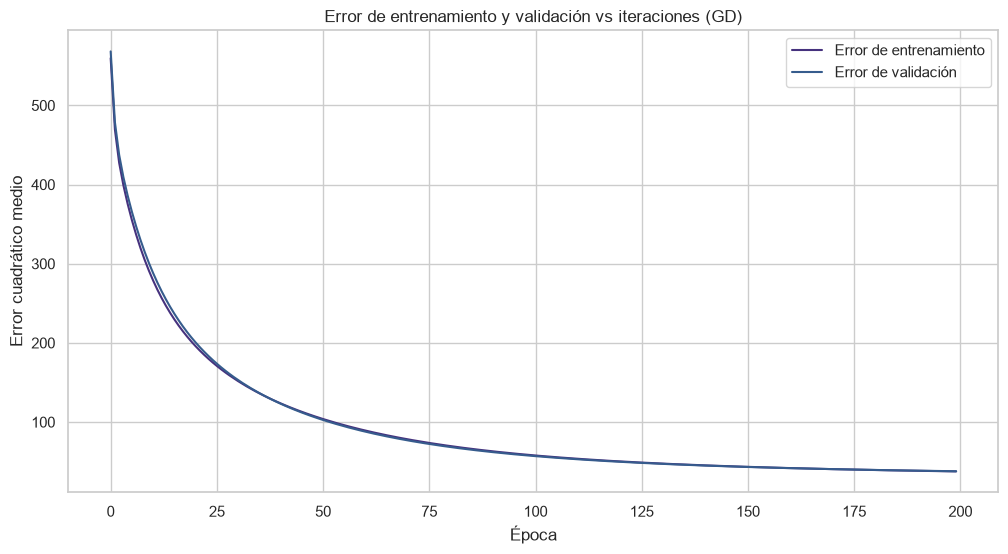

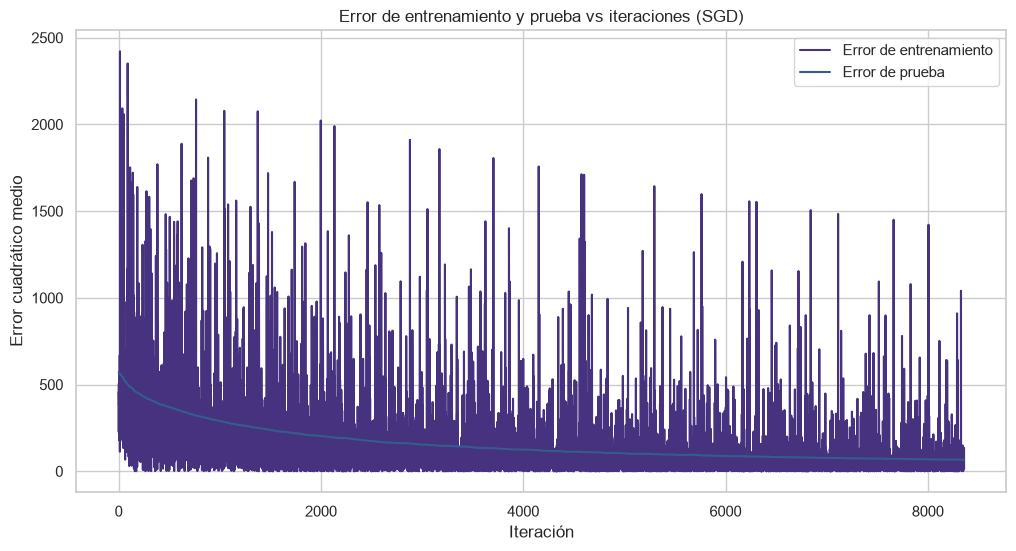

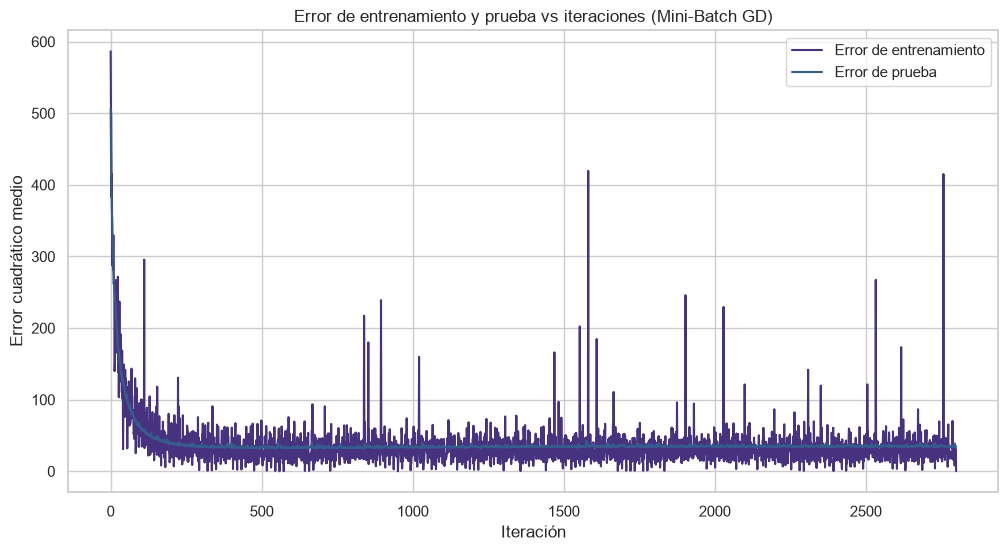

In [59]:
# Vector objetivo como columna.
y_train_columna = y_train.values.reshape(-1, 1)
y_test_columna = y_test.values.reshape(-1, 1)

# Devuelven el vector de pesos W (bias en la posición 0) y no un modelo con .predict().
def predecir_con_pesos(X, W):
    X_con_bias = np.hstack((np.ones((X.shape[0], 1)), X))
    return (X_con_bias @ W).ravel()

np.random.seed(RANDOM_STATE)
W_gd = gradient_descent(X_train_escalado, y_train_columna, X_test_escalado, y_test_columna, lr = 0.01, epochs = 200)

np.random.seed(RANDOM_STATE)
W_sgd = stochastic_gradient_descent(X_train_escalado, y_train_columna, X_test_escalado, y_test_columna, lr = 0.0001, epochs = 20)

np.random.seed(RANDOM_STATE)
W_mbgd = mini_batch_gradient_descent(X_train_escalado, y_train_columna, X_test_escalado, y_test_columna, lr = 0.01, epochs = 200, batch_size = 32)

In [60]:
# Las tres variantes, identificadas por su vector de pesos.
pesos_gradiente = {
    'GD por lotes' : W_gd,
    'GD estocástico' : W_sgd,
    'GD mini-batch' : W_mbgd,
}

# Métricas en train y test de cada variante: contrastar ambos conjuntos es lo que revela sobreajuste.
metricas_gd = pd.concat({
    nombre : pd.DataFrame({
        'train' : calcular_metricas(y_train, predecir_con_pesos(X_train_escalado, W)),
        'test' : calcular_metricas(y_test, predecir_con_pesos(X_test_escalado, W))
    })
    for nombre, W in pesos_gradiente.items()
}, axis = 1)

# Comparativa en test: las tres variantes contra la solución analítica de OLS.
comparacion_gradiente = pd.DataFrame({'Regresión Lineal Múltiple (Mínimos Cuadrados)' : metricas_lineal['test']})

for nombre, W in pesos_gradiente.items():
    comparacion_gradiente[nombre] = calcular_metricas(y_test, predecir_con_pesos(X_test_escalado, W))

print(f"\n Descenso del gradiente, train vs. test: \n{metricas_gd}")
print(f"\n Comparativa en el conjunto de prueba: \n{comparacion_gradiente}")

# Comparativa coeficientes.
comparacion_coeficientes = pd.DataFrame({'OLS' : regresion_lineal.coef_}, index = X_train.columns)
interceptos = {'OLS' : regresion_lineal.intercept_}

for nombre, W in pesos_gradiente.items():
    comparacion_coeficientes[nombre] = W[1:].ravel()
    interceptos[nombre] = W[0][0]

print(f"\n Interceptos: \n{pd.Series(interceptos)}")
print(f"\n Coeficientes: \n{comparacion_coeficientes}")



 Descenso del gradiente, train vs. test: 
     GD por lotes       GD estocástico       GD mini-batch      
            train  test          train  test         train  test
R2          0.559 0.603          0.210 0.308         0.662 0.637
RMSE        6.131 6.147          8.209 8.119         5.367 5.875
MAE         4.183 4.241          6.481 6.366         3.718 3.904

 Comparativa en el conjunto de prueba: 
      Regresión Lineal Múltiple (Mínimos Cuadrados)  GD por lotes  GD estocástico  GD mini-batch
R2                                            0.647         0.603           0.308          0.637
RMSE                                          5.798         6.147           8.119          5.875
MAE                                           3.864         4.241           6.366          3.904

 Interceptos: 
OLS              22.162
GD por lotes     19.287
GD estocástico   14.434
GD mini-batch    22.210
dtype: float64

 Coeficientes: 
           OLS  GD por lotes  GD estocástico  GD mini-batch

## Métodos de Regularización

A continuación, se prueban métodos de regularización **Ridge**, **Lasso** y **ElasticNet** para combatir la multicolinealidad y observar si existe una mejora en el rendimiento de los modelos.

La selección de la intensidad de regularización ($\alpha$) y del balance (`l1_ratio`) se realiza mediante validación cruzada de 5 pliegues (5-Fold CV) exclusivamente sobre el conjunto de entrenamiento para evitar fuga de información (data leakage).

In [61]:
from sklearn.compose import ColumnTransformer

# Separar CHAS del resto de las variables predictoras
columnas_knn = [col for col in X_train.columns if col != 'CHAS']

# Preprocesar cada fold: escalar e imputar las numéricas con KNN;
# imputar CHAS con la categoría más frecuente.
preprocesador = ColumnTransformer(
    transformers=[
        ('numericas', Pipeline([
            ('escalador', RobustScaler()),
            ('imputador', KNNImputer(n_neighbors=5, weights='distance'))
        ]), columnas_knn),
        ('chas', SimpleImputer(strategy='most_frequent'), ['CHAS'])
    ],
    remainder='drop'
)

# Usar los mismos pliegues para comparar los modelos
pliegues = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grilla_alphas = np.logspace(-4, 3, 50)

# Definir modelos y combinaciones de hiperparámetros
modelos_y_parametros = {
    'Ridge': (Ridge(), {'modelo__alpha': grilla_alphas}),
    'Lasso': (Lasso(max_iter=10000), {'modelo__alpha': grilla_alphas}),
    'ElasticNet': (
        ElasticNet(max_iter=10000),
        {'modelo__alpha': grilla_alphas, 'modelo__l1_ratio': [0.01, 0.05, 0.1, 0.5, 0.9]}
    )
}

# Buscar los mejores hiperparámetros mediante validación cruzada
mejores_modelos = {}
mejores_params = {}

for nombre, (modelo, parametros) in modelos_y_parametros.items():
    pipeline = Pipeline([
        ('preprocesador', preprocesador),
        ('modelo', modelo)
    ])

    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros,
        cv=pliegues,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )

    busqueda.fit(X_train, y_train)
    mejores_modelos[nombre] = busqueda.best_estimator_
    mejores_params[nombre] = busqueda.best_params_

    print(f'{nombre}: {busqueda.best_params_}')
    print(f'RMSE de validación: {-busqueda.best_score_:.3f}')

# Verificación: ningún hiperparámetro óptimo puede quedar en el borde de su grilla.
grillas = {'modelo__alpha': grilla_alphas, 'modelo__l1_ratio': [0.01, 0.05, 0.1, 0.5, 0.9]}

for nombre, params in mejores_params.items():
    for clave, valor in params.items():
        en_borde = valor in (min(grillas[clave]), max(grillas[clave]))
        print(f"{nombre} {clave}: {valor} -> en el borde: {'sí' if en_borde else 'no'}")


Ridge: {'modelo__alpha': np.float64(2.682695795279722)}
RMSE de validación: 5.641
Lasso: {'modelo__alpha': np.float64(0.026826957952797246)}
RMSE de validación: 5.654
ElasticNet: {'modelo__alpha': np.float64(0.01), 'modelo__l1_ratio': 0.05}
RMSE de validación: 5.641
Ridge modelo__alpha: 2.682695795279722 -> en el borde: no
Lasso modelo__alpha: 0.026826957952797246 -> en el borde: no
ElasticNet modelo__alpha: 0.01 -> en el borde: no
ElasticNet modelo__l1_ratio: 0.05 -> en el borde: no


In [62]:
# Métricas en test de OLS, gradiente y los tres modelos regularizados.
# Los pipelines reciben X sin escalar: el preprocesador va adentro.
comparativa_regularizacion = pd.DataFrame({
    'Regresión Lineal Múltiple (Mínimos Cuadrados)' : metricas_lineal['test']
})

for nombre, W in pesos_gradiente.items():
    comparativa_regularizacion[nombre] = calcular_metricas(y_test, predecir_con_pesos(X_test_escalado, W))

for nombre, modelo in mejores_modelos.items():
    comparativa_regularizacion[nombre] = calcular_metricas(y_test, modelo.predict(X_test))

print(f"\n Comparativa de rendimiento en test \n{comparativa_regularizacion}")

# Coeficientes de todos los modelos, alineados con las columnas de X_train.
df_coeficientes = pd.DataFrame({'OLS' : regresion_lineal.coef_}, index = X_train.columns)

for nombre, W in pesos_gradiente.items():
    df_coeficientes[nombre] = W[1:].ravel()          # el bias ocupa la posición 0

# El preprocesador pone las numéricas primero y CHAS al final: se reordena para coincidir con X_train.
nombres_pipeline = columnas_knn + ['CHAS']

for nombre, modelo in mejores_modelos.items():
    coeficientes = modelo.named_steps['modelo'].coef_
    df_coeficientes[nombre] = pd.Series(coeficientes, index = nombres_pipeline).reindex(X_train.columns)

print(f"\n Coeficientes por modelo \n{df_coeficientes}")

# Variables descartadas: coeficiente exactamente cero.
print("\n Variables descartadas (coeficiente exactamente cero)")

for nombre in df_coeficientes.columns:
    descartadas = df_coeficientes.index[df_coeficientes[nombre] == 0].tolist()
    print(f"  {nombre:20s}: {descartadas if descartadas else 'ninguna'}")



 Comparativa de rendimiento en test 
      Regresión Lineal Múltiple (Mínimos Cuadrados)  GD por lotes  GD estocástico  GD mini-batch  Ridge  Lasso  ElasticNet
R2                                            0.647         0.603           0.308          0.637  0.647  0.646       0.647
RMSE                                          5.798         6.147           8.119          5.875  5.800  5.807       5.797
MAE                                           3.864         4.241           6.366          3.904  3.801  3.802       3.794

 Coeficientes por modelo 
           OLS  GD por lotes  GD estocástico  GD mini-batch  Ridge  Lasso  ElasticNet
CRIM     0.341         0.222           0.419          0.393  0.357  0.353       0.362
ZN       1.317         1.672           3.495          1.263  1.238  1.224       1.209
INDUS    1.191         2.118           2.219          0.659  0.724  0.409       0.580
CHAS     6.400         2.577           1.489          6.677  6.076  6.278       5.903
NOX     -2.45

## Análisis de Resultados

Para analizar la performance de los modelos, se hace una comparación de las métricas obtenidas anteriormente.

In [63]:
def calcular_metricas_completas(y_real, y_predicho):
    return {
        "R2": r2_score(y_real, y_predicho),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_predicho)),
        "MAE": mean_absolute_error(y_real, y_predicho),
        "MAPE (%)": mean_absolute_percentage_error(y_real, y_predicho) * 100,
    }

# Predicciones de cada modelo.
predicciones = {
    "Mínimos Cuadrados": (regresion_lineal.predict(X_train_escalado),
                          regresion_lineal.predict(X_test_escalado)),
}

for nombre, W in pesos_gradiente.items():
    predicciones[nombre] = (predecir_con_pesos(X_train_escalado, W),
                            predecir_con_pesos(X_test_escalado, W))

# Los pipelines de regularización reciben X sin escalar: el preprocesador va adentro.
for nombre, modelo in mejores_modelos.items():
    predicciones[nombre] = (modelo.predict(X_train), modelo.predict(X_test))

# Construcción de la tabla comparativa.
filas_metricas = []

for nombre, (y_tr_pred, y_te_pred) in predicciones.items():
    m_train = calcular_metricas_completas(y_train, y_tr_pred)
    m_test = calcular_metricas_completas(y_test, y_te_pred)

    filas_metricas.append(
        {
            "Modelo": nombre,
            "R2 (Train)": m_train["R2"],
            "R2 (Test)": m_test["R2"],
            "RMSE (Train)": m_train["RMSE"],
            "RMSE (Test)": m_test["RMSE"],
            "MAE (Train)": m_train["MAE"],
            "MAE (Test)": m_test["MAE"],
            "MAPE % (Train)": m_train["MAPE (%)"],
            "MAPE % (Test)": m_test["MAPE (%)"],
        }
    )

df_metricas_comparativas = pd.DataFrame(filas_metricas).set_index("Modelo")

display(df_metricas_comparativas)

,R2 (Train),R2 (Test),RMSE (Train),RMSE (Test),MAE (Train),MAE (Test),MAPE % (Train),MAPE % (Test)
Modelo,,,,,,,,
Mínimos Cuadrados,0.668,0.647,5.325,5.798,3.654,3.864,18.097,19.123
GD por lotes,0.559,0.603,6.131,6.147,4.183,4.241,20.465,21.593
GD estocástico,0.210,0.308,8.209,8.119,6.481,6.366,29.975,30.793
GD mini-batch,0.662,0.637,5.367,5.875,3.718,3.904,18.859,19.761
Ridge,0.666,0.647,5.336,5.800,3.621,3.801,17.903,18.805
Lasso,0.666,0.646,5.338,5.807,3.624,3.802,17.919,18.782
ElasticNet,0.665,0.647,5.345,5.797,3.616,3.794,17.880,18.786


En el conjunto de prueba, la regresión lineal por mínimos cuadrados obtuvo un $R^2$ de 0,647, un RMSE de 5,798 y un MAE de 3,864 miles de USD. Esto indica que el modelo explica alrededor del 65 % de la variabilidad de `MEDV`; el error absoluto medio de sus predicciones es de aproximadamente 3.864 USD.

Ridge, Lasso y ElasticNet alcanzaron resultados prácticamente iguales a los de mínimos cuadrados: sus valores de $R^2$ en prueba van de 0,646 a 0,647 y sus RMSE, de 5,798 a 5,807 miles de USD. Aunque redujeron levemente el MAE, las diferencias son pequeñas y no muestran una mejora relevante en la capacidad predictiva. La tabla de coeficientes tampoco muestra variables anuladas exactamente por Lasso o ElasticNet.

Entre las variantes del descenso por el gradiente, mini-batch fue la más cercana a mínimos cuadrados ($R^2$ de 0,637 y RMSE de 5,875 en prueba). El descenso por lotes obtuvo un desempeño inferior ($R^2$ de 0,603), y el estocástico fue el más débil ($R^2$ de 0,308). Por lo tanto, con las tasas de aprendizaje y épocas utilizadas, las variantes iterativas no superaron al ajuste analítico.

Las métricas de entrenamiento y prueba son cercanas para mínimos cuadrados y los modelos regularizados, lo que no indica un sobreajuste marcado en esta partición. Sin embargo, el modelo lineal deja sin explicar cerca del 35 % de la variabilidad de `MEDV`. Los resultados permiten concluir que la regularización no produjo una mejora apreciable en esta evaluación; el desempeño observado corresponde a los modelos lineales probados y no permite afirmar, por sí solo, que otras formas de modelar la relación entre las variables no pudieran mejorar la predicción.

Por otro lado, el RMSE permite comparar los modelos en la misma unidad que la variable objetivo y, además, penaliza con mayor intensidad los errores grandes. En este caso, los valores de los modelos de mínimos cuadrados, Ridge, Lasso y ElasticNet se mantienen entre 5,798 y 5,807 miles de USD: la diferencia es de apenas 0,009 miles de USD, por lo que no representa una mejora práctica. Mini-batch obtuvo un RMSE de 5,875, mientras que el descenso por lotes y el estocástico alcanzaron 6,147 y 8,119, respectivamente. Así, el RMSE refuerza que los modelos regularizados rinden de manera muy similar a mínimos cuadrados y que, con la configuración utilizada, las variantes del gradiente tuvieron errores mayores.

Para complementar las métricas, se analizan los residuos y se comparan los valores predichos con los reales en el conjunto de prueba.

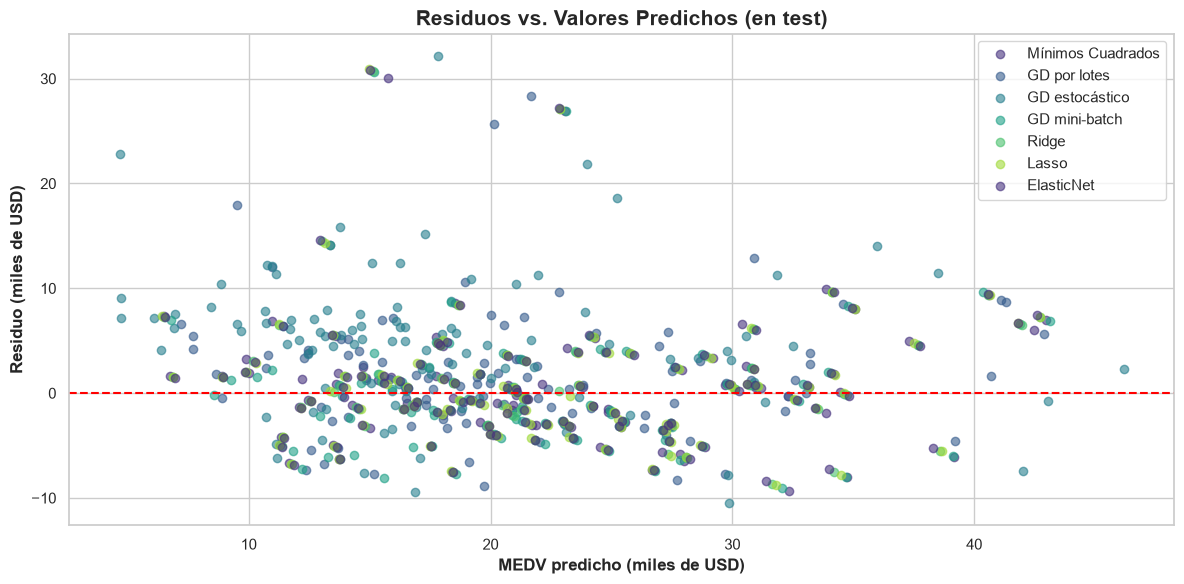

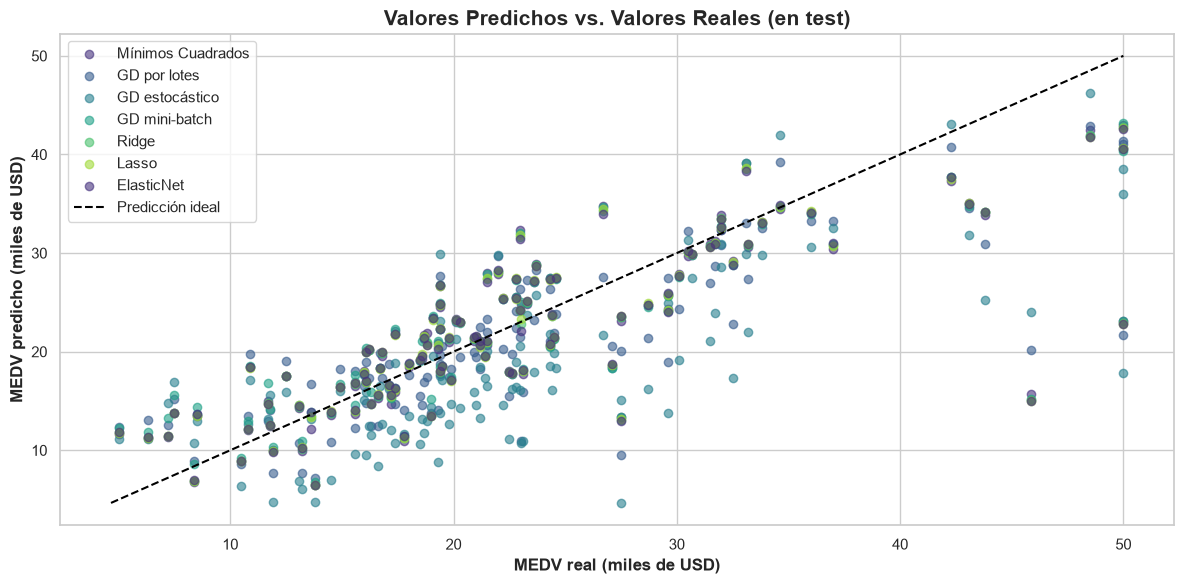

In [64]:
# Predicciones para cada modelo en el conjunto de prueba
predicciones_test = {
    'Mínimos Cuadrados': regresion_lineal.predict(X_test_escalado),
    'GD por lotes': predecir_con_pesos(X_test_escalado, W_gd),
    'GD estocástico': predecir_con_pesos(X_test_escalado, W_sgd),
    'GD mini-batch': predecir_con_pesos(X_test_escalado, W_mbgd),
}

# Los pipelines de regularización reciben X_test sin escalar
for nombre, modelo in mejores_modelos.items():
    predicciones_test[nombre] = modelo.predict(X_test)

# Grfico de Residuos vs. Predichos
fig, ax = plt.subplots()

for nombre, y_predicho in predicciones_test.items():
    residuos = y_test.to_numpy() - y_predicho
    ax.scatter(y_predicho, residuos, alpha=0.6, label=nombre)

ax.axhline(0, color='red', linestyle='--')
ax.set_title('Residuos vs. Valores Predichos (en test)', fontweight = 'bold', fontsize = 15)
ax.set_xlabel('MEDV predicho (miles de USD)', fontweight = 'bold')
ax.set_ylabel('Residuo (miles de USD)', fontweight = 'bold')
ax.legend()
plt.tight_layout()
plt.show()

# Grafico de Predichos vs. Reales
fig, ax = plt.subplots()

for nombre, y_predicho in predicciones_test.items():
    ax.scatter(y_test, y_predicho, alpha=0.6, label=nombre)

limite_min = min(y_test.min(), min(pred.min() for pred in predicciones_test.values()))
limite_max = max(y_test.max(), max(pred.max() for pred in predicciones_test.values()))

ax.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    color='black',
    linestyle='--',
    label='Predicción ideal'
)
ax.set_title('Valores Predichos vs. Valores Reales (en test)', fontweight = 'bold', fontsize = 15)
ax.set_xlabel('MEDV real (miles de USD)', fontweight = 'bold')
ax.set_ylabel('MEDV predicho (miles de USD)', fontweight = 'bold')
ax.legend()
plt.tight_layout()
plt.show()

En el gráfico de residuos, la mayoría de los modelos concentra sus puntos alrededor de cero, aunque aparecen errores grandes y algunos residuos positivos elevados. Como el residuo se calculó como valor real menos predicho, esos valores positivos indican observaciones cuyo precio fue subestimado. 

En el gráfico de predicciones frente a valores reales, mínimos cuadrados y los modelos regularizados se superponen y siguen la tendencia de la diagonal, aunque con dispersión. En los precios reales más altos se observan varias subestimaciones; el descenso estocástico, por su parte, presenta mayor dispersión, en línea con sus métricas más desfavorables.

## Optimización de Hiperparámetros

### Gradiente Descendiente

Se varían los siguientes hiperparámetros:

* **Learning rate ($\alpha$)**: el tamaño del paso en la regla $\beta^{nuevo} = \beta^{viejo} - \alpha \cdot \frac{\partial MSE}{\partial \beta}$.

* **Épocas**: cuántas veces se recorre el conjunto de entrenamiento. Se fijan en 150 para todas las pruebas.

* **Tamaño del lote**: cuántas observaciones intervienen en cada actualización.

Como referencia se toma el MSE de entrenamiento de OLS, que es el mínimo exacto al que el descenso por el gradiente intenta llegar.

In [65]:
def entrenar_con_gradiente(lr, epochs = 150):
    np.random.seed(RANDOM_STATE)
    W = gradient_descent(X_train_escalado, y_train_columna, X_test_escalado, y_test_columna, lr = lr, epochs = epochs)
    return W, mean_squared_error(y_train, predecir_con_pesos(X_train_escalado, W))

mse_train_ols = mean_squared_error(y_train, regresion_lineal.predict(X_train_escalado))

print(f"Mínimo alcanzable (MSE de entrenamiento de la regresión lineal): {mse_train_ols:.3f}")

Mínimo alcanzable (MSE de entrenamiento de la regresión lineal): 28.350


#### Variación del learning rate ($\alpha$)

Se mantienen fijas las 150 épocas y se prueban distintos valores de $\alpha$.


 Learning rate = 0.0001


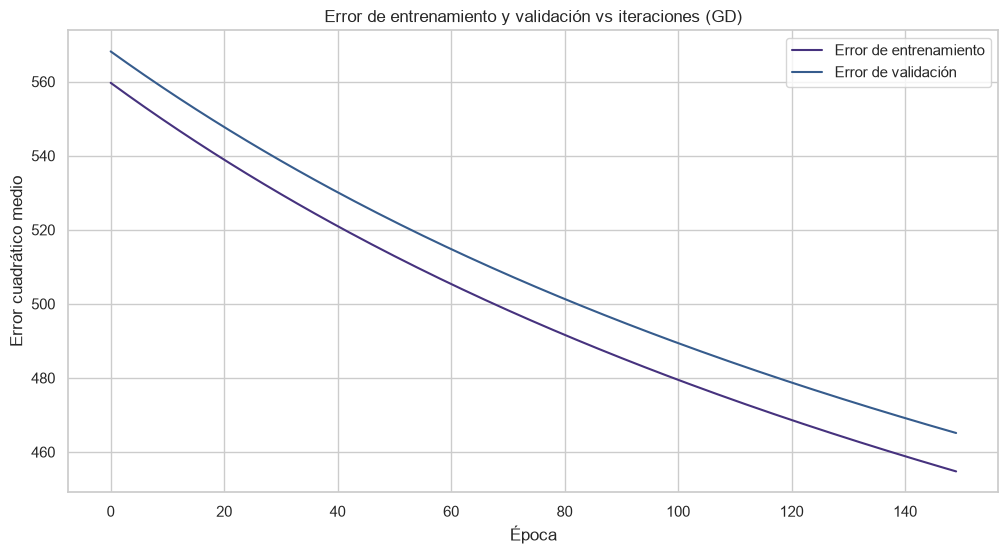


 Learning rate = 0.001


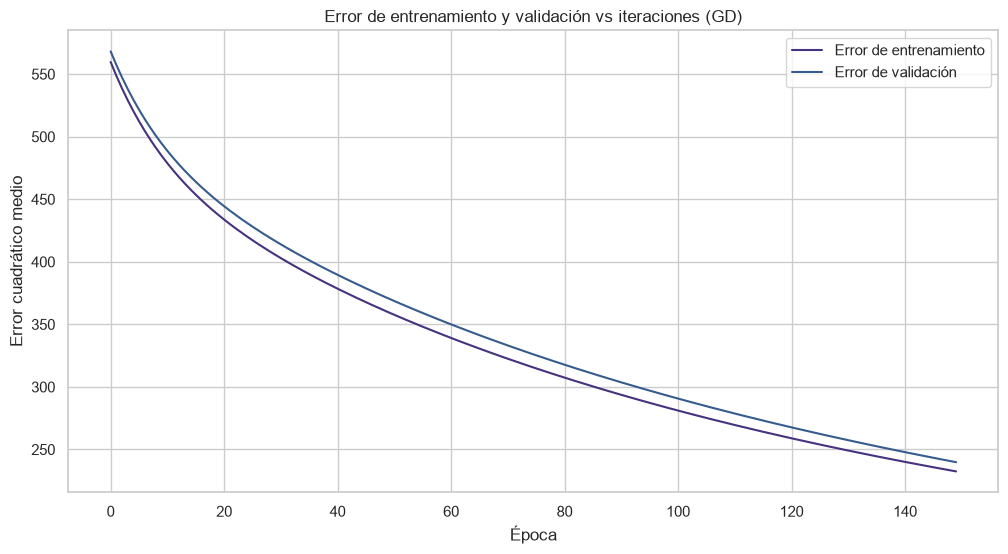


 Learning rate = 0.01


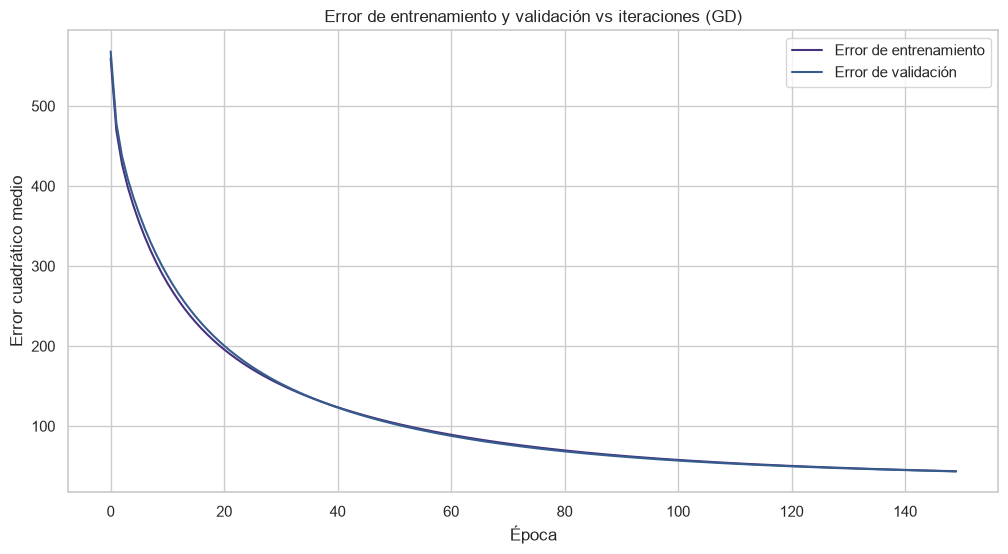


 Learning rate = 0.1


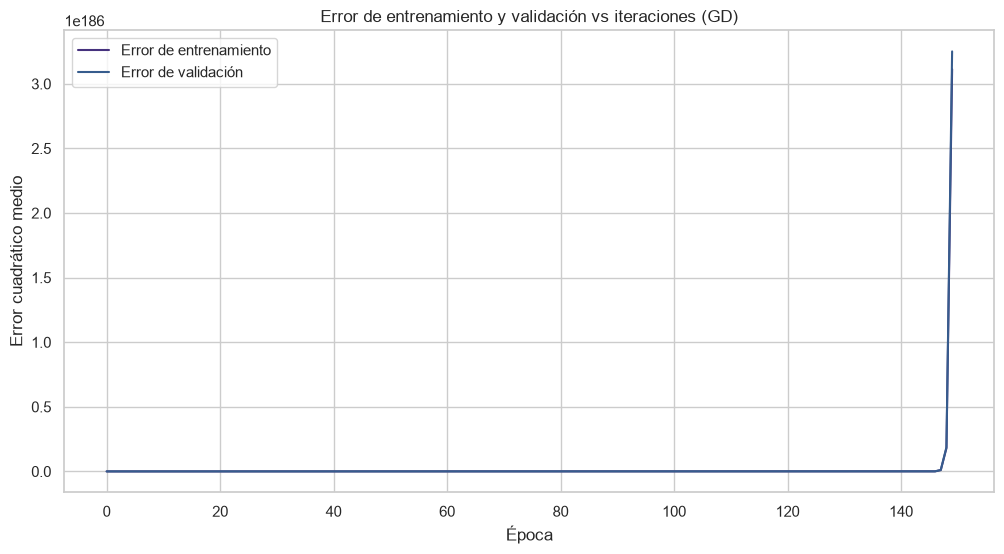


 MSE de entrenamiento alcanzado en 150 épocas: 
              MSE final (train)           resultado
learning rate                                      
0.0001                  454.315  no llega al mínimo
0.001                   231.644  no llega al mínimo
0.01                     43.408  no llega al mínimo
0.1                  5.398e+187             diverge

 Mínimo alcanzable (OLS): 28.350


In [66]:
mse_por_learning_rate = {}

for learning_rate in [0.0001, 0.001, 0.01, 0.1]:
    print(f"\n Learning rate = {learning_rate}")
    _, mse_final = entrenar_con_gradiente(lr = learning_rate)
    mse_por_learning_rate[learning_rate] = mse_final

resumen_learning_rate = pd.DataFrame({
    'learning rate' : [f"{lr:g}" for lr in mse_por_learning_rate],
    'MSE final (train)' : [f"{mse:,.3f}" if mse < 1e6 else f"{mse:.3e}"
                           for mse in mse_por_learning_rate.values()],
    'resultado' : ['diverge' if mse > 1e6 else ('converge' if mse < 30 else 'no llega al mínimo')
                   for mse in mse_por_learning_rate.values()]
}).set_index('learning rate')

print(f"\n MSE de entrenamiento alcanzado en 150 épocas: \n{resumen_learning_rate}")
print(f"\n Mínimo alcanzable (OLS): {mse_train_ols:.3f}")

#### Variación del tamaño del lote

El tamaño del lote determina cuántas observaciones intervienen en cada actualización de los pesos y funciona como puente entre las dos variantes extremas: con `batch_size` = 1 el algoritmo equivale al descenso estocástico, y con `batch_size` = 418 (el total de observaciones de entrenamiento) equivale al descenso por lotes.

Se fija $\alpha$ = 0,01 y 150 épocas, y se varía únicamente el tamaño del lote.


Batch size = 1


c:\Users\Juli\OneDrive\Escritorio\TP_AA1_Aiup_Paoloni_Silva\.venv\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\Juli\AppData\Local\Temp\ipykernel_42688\146849813.py:362: RuntimeWarning: overflow encountered in square
  test_mse = np.mean(error_test ** 2)
C:\Users\Juli\AppData\Local\Temp\ipykernel_42688\146849813.py:353: RuntimeWarning: overflow encountered in square
  train_mse = np.mean(error ** 2)
C:\Users\Juli\AppData\Local\Temp\ipykernel_42688\146849813.py:356: RuntimeWarning: overflow encountered in multiply
  gradient = -2 * np.matmul(x_batch.T, error) / batch_size
C:\Users\Juli\AppData\Local\Temp\ipykernel_42688\146849813.py:360: RuntimeWarning: invalid value encountered in matmul
  prediction_test = np.matmul(X_test, W)
C:\Users\Juli\AppData\Local\Temp\ipykernel_42688\146849813.py:356: RuntimeWarning: invalid value encountered in matmul
  gradient = -2 * np.mat

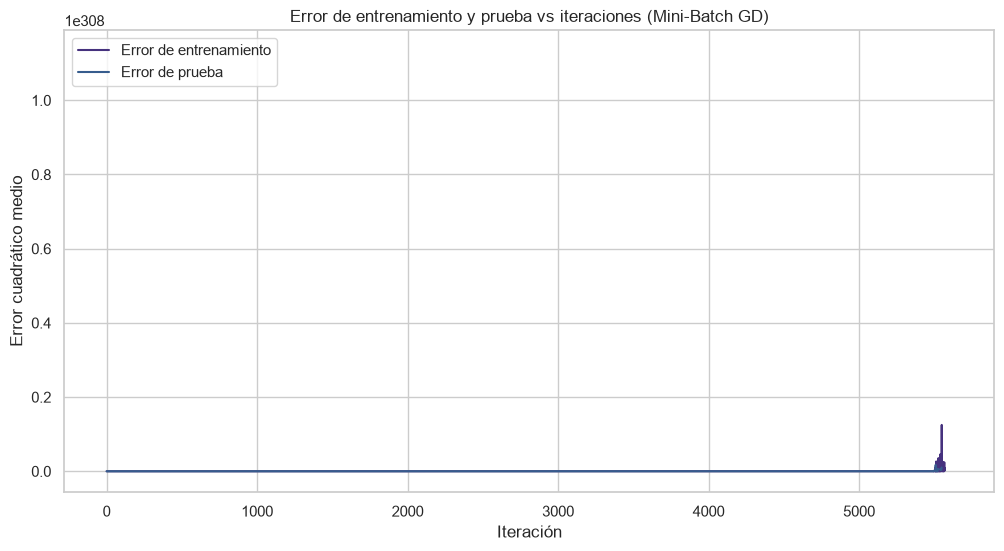


Batch size = 8


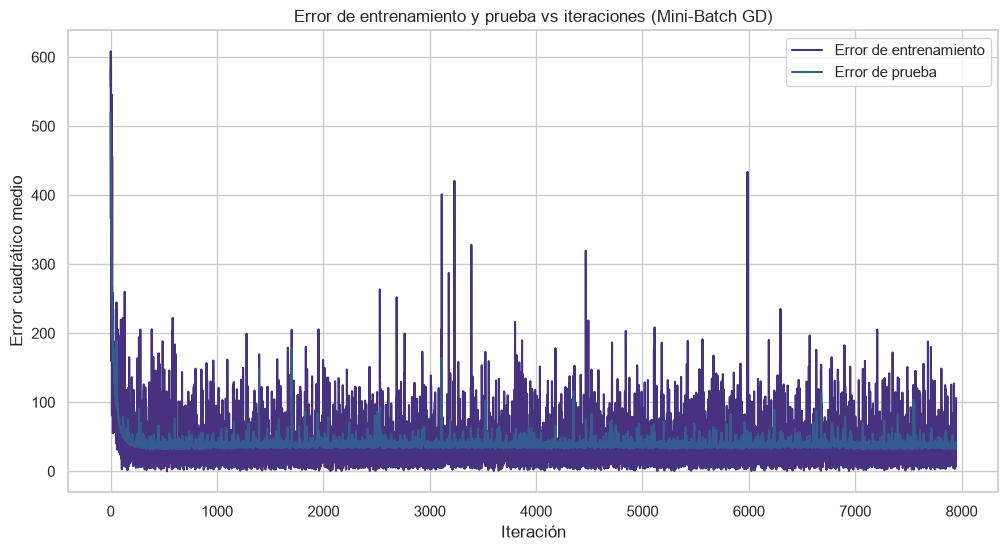


Batch size = 32


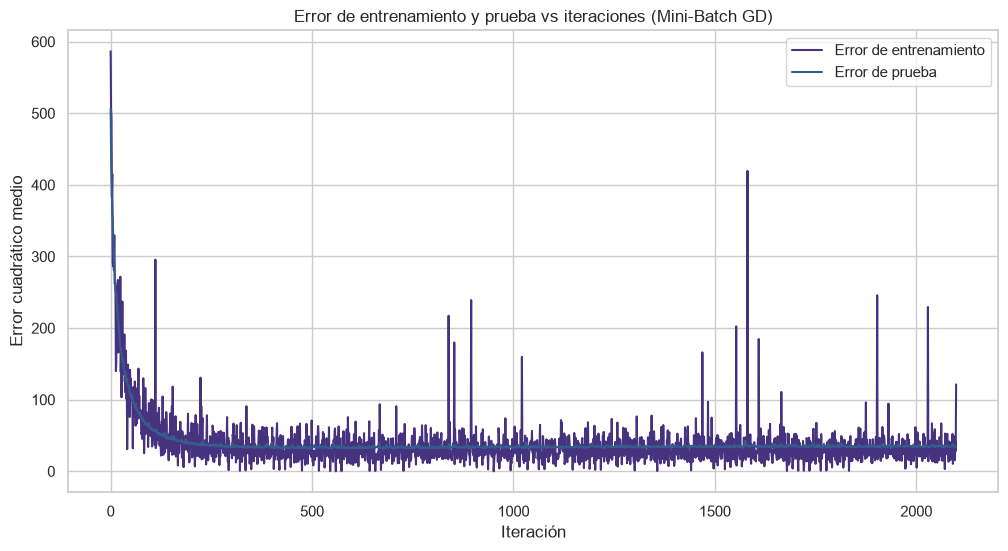


Batch size = 128


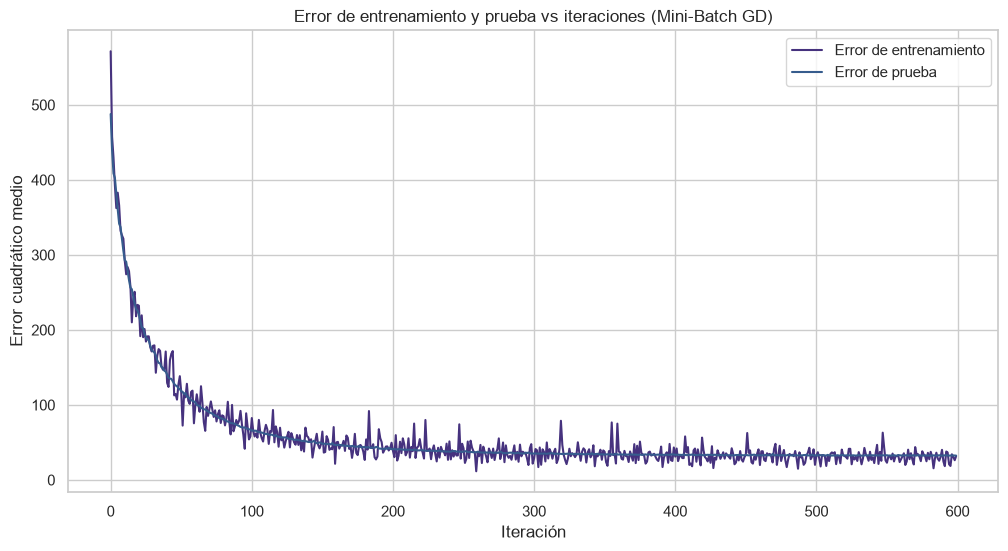


Batch size = 418


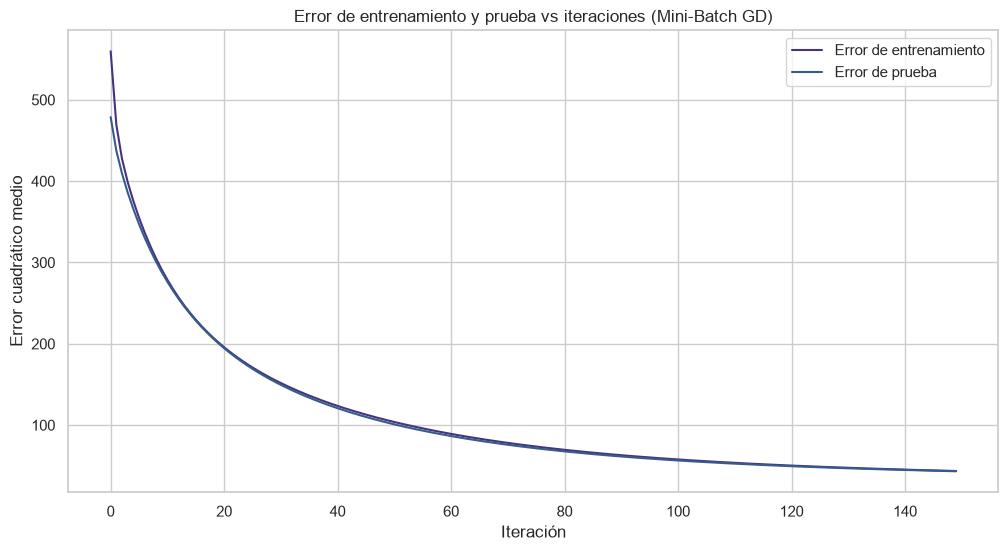


Resultado después de 150 épocas:
            MSE final (train) resultado
batch size                             
1                         NaN   diverge
8                      44.540   estable
32                     29.593   estable
128                    30.421   estable
418                    43.408   estable

Mínimo alcanzable (OLS): 28.350


In [67]:
mse_por_lote = {}
resultado_por_lote = {}

tamanos_lote = [1, 8, 32, 128, X_train_escalado.shape[0]]

for tamano_lote in tamanos_lote:
    print(f"\nBatch size = {tamano_lote}")
    np.random.seed(RANDOM_STATE)

    W_lote = mini_batch_gradient_descent(
        X_train_escalado,
        y_train_columna,
        X_test_escalado,
        y_test_columna,
        lr=0.01,
        epochs=150,
        batch_size=tamano_lote
    )

    if np.isfinite(W_lote).all():
        mse_por_lote[tamano_lote] = mean_squared_error(
            y_train,
            predecir_con_pesos(X_train_escalado, W_lote)
        )
        resultado_por_lote[tamano_lote] = 'estable'
    else:
        mse_por_lote[tamano_lote] = np.nan
        resultado_por_lote[tamano_lote] = 'diverge'

resumen_lote = pd.DataFrame({
    'MSE final (train)': mse_por_lote,
    'resultado': resultado_por_lote
})
resumen_lote.index.name = 'batch size'

print(f"\nResultado después de 150 épocas:\n{resumen_lote}")
print(f"\nMínimo alcanzable (OLS): {mse_train_ols:.3f}")

### Análisis de resultados

Con 150 épocas, el MSE de entrenamiento de OLS fue **28,350** y se utiliza como referencia para evaluar el descenso por el gradiente.

**Efecto del learning rate.** Con $\alpha = 0,0001$ y $\alpha = 0,001$, los MSE finales fueron **454,315** y **231,644**: en el número de épocas probado, los pasos pequeños no acercaron suficientemente el modelo al valor de referencia. Con $\alpha = 0,01$, el MSE fue **43,408**, todavía por encima del de OLS. En cambio, $\alpha = 0,1$ hizo que el algoritmo divergiera. Ninguno de los valores probados alcanzó el MSE de OLS.

**Efecto del tamaño del lote.** Al fijar $\alpha = 0,01$, el mejor resultado entre los tamaños evaluados se obtuvo con `batch_size = 32`, con un MSE de **29,593**. Le siguió el lote de 128 observaciones, con **30,421**. Los lotes de 8 y 418 obtuvieron **44,540** y **43,408**, respectivamente. Con `batch_size = 1`, el algoritmo divergió.

En estas pruebas, el `learning rate` y el tamaño del lote afectaron cuánto pudo avanzar el algoritmo en las 150 épocas. Entre las configuraciones evaluadas, $\alpha = 0,01$ y `batch_size = 32` fue la que más se acercó al MSE de OLS, aunque quedó por encima. Estos resultados describen las configuraciones probadas y muestran que una elección inadecuada puede impedir la convergencia o provocar divergencia.

### Ridge y Lasso

Se prueban valores de $\lambda$ entre 0,0001 y 1.000 y, para cada uno, se calcula el error con validación cruzada sobre el conjunto de entrenamiento. Se elige el $\lambda$ con menor error.

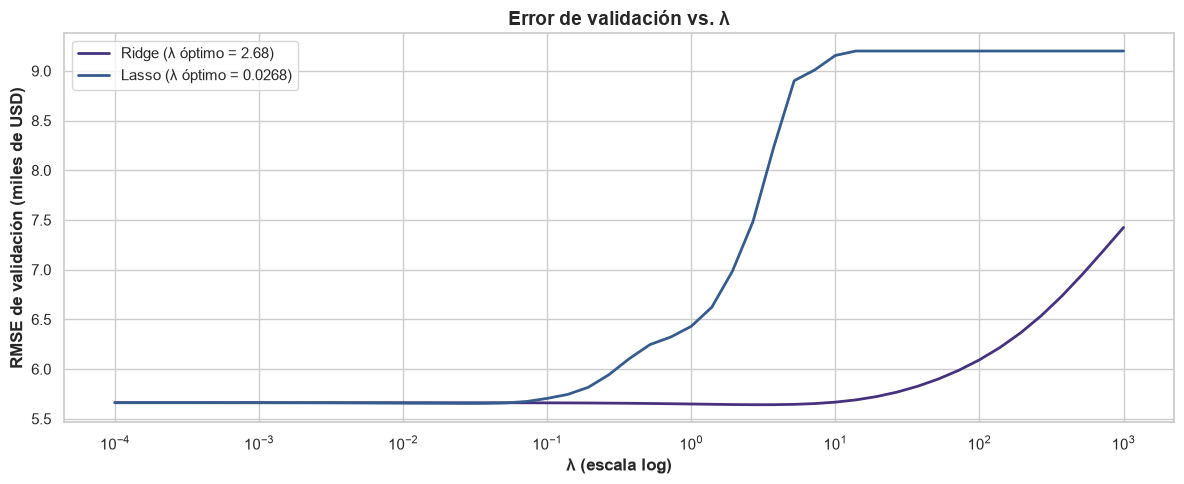

λ óptimo de Ridge: 2.6827 | regularización: 2.6827
λ óptimo de Lasso: 0.0268 | regularización: 0.0268


In [68]:
modelos_penalizados = {
    'Ridge': Ridge(),
    'Lasso': Lasso(max_iter=10000)
}

rmse_validacion = {nombre: [] for nombre in modelos_penalizados}

# Evaluar cada lambda mediante validación cruzada
for nombre, modelo in modelos_penalizados.items():
    tuberia = Pipeline([
        ('preprocesador', preprocesador),
        ('modelo', modelo)
    ])

    for alpha in grilla_alphas:
        tuberia.set_params(modelo__alpha=alpha)

        rmse = -cross_val_score(
            tuberia,
            X_train,
            y_train,
            cv=pliegues,
            scoring='neg_root_mean_squared_error'
        ).mean()

        rmse_validacion[nombre].append(rmse)

# Lambda con menor RMSE de validación
alpha_optimo = {
    nombre: grilla_alphas[np.argmin(rmse)]
    for nombre, rmse in rmse_validacion.items()
}

# Conservar estos nombres para las celdas siguientes
alpha_ridge = alpha_optimo['Ridge']
alpha_lasso = alpha_optimo['Lasso']

# Graficar RMSE de validación según lambda
fig, ax = plt.subplots(figsize=(12, 5))

for nombre, rmse in rmse_validacion.items():
    ax.plot(
        grilla_alphas,
        rmse,
        linewidth=2,
        label=f"{nombre} (λ óptimo = {alpha_optimo[nombre]:.3g})"
    )

ax.set_xscale('log')
ax.set_title('Error de validación vs. λ', fontweight='bold', fontsize=14)
ax.set_xlabel('λ (escala log)', fontweight='bold')
ax.set_ylabel('RMSE de validación (miles de USD)', fontweight='bold')
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

# Comparar con los valores seleccionados en la sección anterior
print(f"λ óptimo de Ridge: {alpha_ridge:.4f} | regularización: "
      f"{mejores_params['Ridge']['modelo__alpha']:.4f}")
print(f"λ óptimo de Lasso: {alpha_lasso:.4f} | regularización: "
      f"{mejores_params['Lasso']['modelo__alpha']:.4f}")

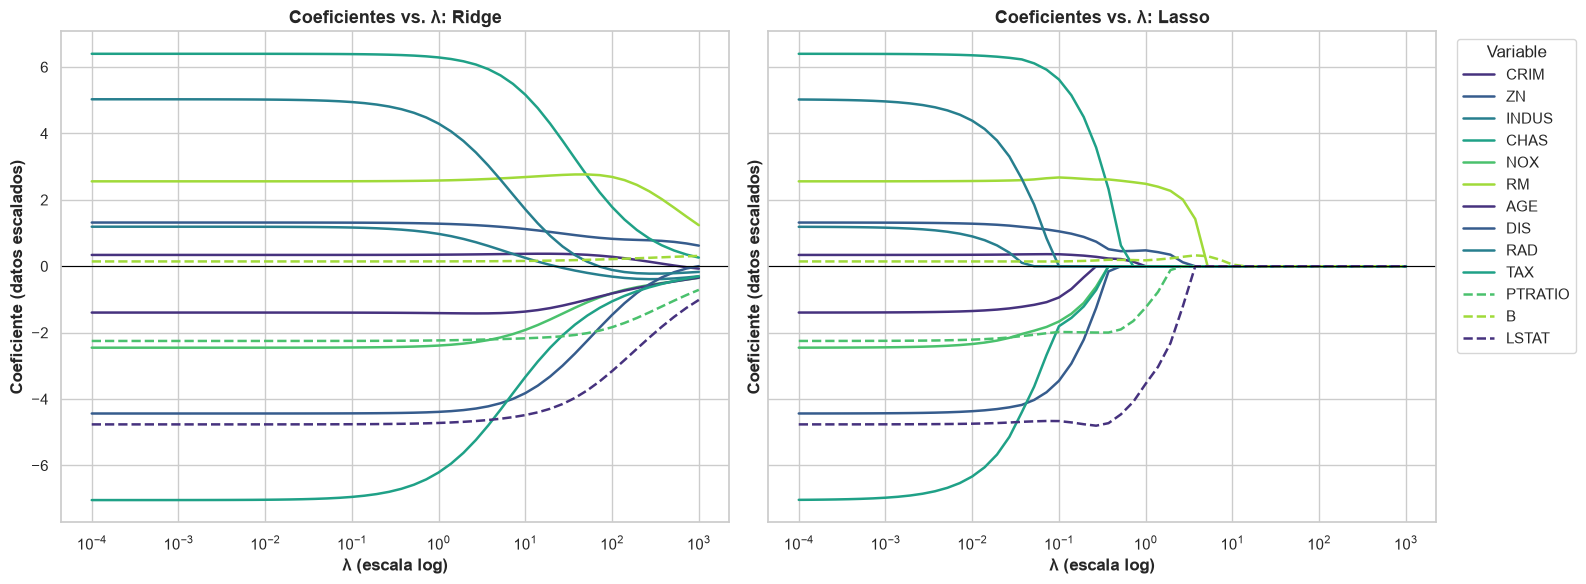

In [69]:
# Coeficientes de cada modelo para cada lambda.
fig, axes = plt.subplots(ncols=2, figsize=(16, 6), sharey=True)

for ax, (nombre, modelo) in zip(axes, modelos_penalizados.items()):
    coeficientes = pd.DataFrame(
        [modelo.set_params(alpha=alpha).fit(X_train_escalado, y_train).coef_ for alpha in grilla_alphas],
        index=grilla_alphas,
        columns=X_train.columns,
    )

    for i, columna in enumerate(coeficientes.columns):
        ax.plot(coeficientes.index, coeficientes[columna], label=columna, linewidth=1.8,
                linestyle="-" if i < 10 else "--")

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_title(f"Coeficientes vs. λ: {nombre}", fontweight="bold", fontsize=13)
    ax.set_xlabel("λ (escala log)", fontweight="bold")
    ax.set_ylabel("Coeficiente (datos escalados)", fontweight="bold")

axes[1].legend(title="Variable", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [70]:
# Se entrenan Ridge y Lasso con el lambda elegido y se comparan con OLS.
ridge_optimo = Ridge(alpha=alpha_optimo["Ridge"]).fit(X_train_escalado, y_train)
lasso_optimo = Lasso(alpha=alpha_optimo["Lasso"], max_iter=10000).fit(X_train_escalado, y_train)

metricas_optimizados = pd.DataFrame(
    {
        "OLS": calcular_metricas(y_test, regresion_lineal.predict(X_test_escalado)),
        "Ridge": calcular_metricas(y_test, ridge_optimo.predict(X_test_escalado)),
        "Lasso": calcular_metricas(y_test, lasso_optimo.predict(X_test_escalado)),
    }
)

print(f"Métricas en el conjunto de prueba:\n{metricas_optimizados}")
print(f"\nVariables que deja afuera Lasso: {X_train.columns[lasso_optimo.coef_ == 0].tolist()}")

Métricas en el conjunto de prueba:
       OLS  Ridge  Lasso
R2   0.647  0.647  0.646
RMSE 5.798  5.800  5.807
MAE  3.864  3.801  3.802

Variables que deja afuera Lasso: []


### Análisis de Resultados

La búsqueda con validación cruzada seleccionó $\lambda = 2,6827$ para Ridge y $\lambda = 0,0268$ para Lasso. Ambos valores coinciden con los obtenidos en la búsqueda anterior mediante `GridSearchCV`.

En la curva de error, valores pequeños de $\lambda$ implican una penalización débil; al aumentarlo, los coeficientes se contraen y el error puede crecer si la penalización es excesiva. Ridge reduce progresivamente todos los coeficientes, mientras que Lasso también puede llevar algunos a cero. Sin embargo, con el $\lambda$ óptimo encontrado, Lasso no anuló ninguna variable.

En el conjunto de prueba, OLS obtuvo un RMSE de 5,798 miles de USD; Ridge, 5,800; y Lasso, 5,807. Las diferencias son mínimas. Ridge y Lasso tuvieron un MAE ligeramente menor que OLS, pero esa mejora no se refleja en el RMSE ni en el $R^2$ de manera relevante. Por lo tanto, con esta partición y estos parámetros, la regularización no aportó una mejora predictiva apreciable ni redujo la cantidad de variables seleccionadas por Lasso.

## Conclusión

Se desarrolló un modelo de regresión para estimar MEDV a partir de 13 variables descriptivas. De las 556 observaciones originales, se eliminaron 21 con el valor objetivo faltante y 12 con más de tres datos faltantes en las predictoras. Las observaciones restantes se dividieron en 418 para entrenamiento y 105 para prueba. El escalado robusto y la imputación se ajustaron usando el conjunto de entrenamiento; los valores atípicos detectados mediante el criterio IQR se conservaron porque pueden representar características reales de los barrios.

En el conjunto de prueba, mínimos cuadrados obtuvo un $R^2$ de 0,647 y un RMSE de 5,798 miles de USD. Ridge, Lasso y ElasticNet lograron resultados prácticamente iguales: sus $R^2$ estuvieron entre 0,646 y 0,647 y sus RMSE entre 5,797 y 5,807 miles de USD. Las pequeñas diferencias en MAE tampoco representan una mejora predictiva importante. En esta ejecución, Lasso y ElasticNet no anularon exactamente ningún coeficiente.

Las variantes del descenso por el gradiente tuvieron resultados distintos según su configuración. Mini-batch fue la más cercana a mínimos cuadrados, con un $R^2$ de 0,637 y un RMSE de 5,875 en prueba. El descenso por lotes obtuvo un RMSE de 6,147 y el estocástico, de 8,119. Con los parámetros utilizados para esta comparación, ninguna superó al ajuste por mínimos cuadrados.

Los gráficos de residuos y de valores predichos frente a reales complementan estas métricas: permiten observar la magnitud y distribución de los errores, así como la cercanía de las predicciones a los valores reales. En conjunto, los resultados de prueba de mínimos cuadrados y los modelos regularizados son muy similares. El $R^2$ de 0,647 indica que el modelo explica alrededor del 65 % de la variabilidad de MEDV, por lo que queda una parte que los modelos lineales evaluados no capturan.

En síntesis, la regularización no produjo una mejora apreciable en el desempeño predictivo de esta partición. La elección entre mínimos cuadrados, Ridge, Lasso y ElasticNet debería considerar también la estabilidad y la simplicidad del modelo, ya que sus métricas son prácticamente equivalentes. Los resultados describen los modelos y parámetros evaluados; por sí solos, no demuestran que una forma lineal sea el único enfoque posible.

**Modelo elegido**. Se selecciona la regresión por mínimos cuadrados como modelo final. Según la métrica priorizada, su RMSE en prueba es 5,798 miles de USD, frente a 5,797 para ElasticNet. La diferencia es de apenas 0,001 miles de USD —aproximadamente 1 USD—, por lo que ambos modelos tienen un desempeño prácticamente equivalente según esta métrica. Se elige OLS por su procedimiento de ajuste más sencillo, sin búsqueda de hiperparámetros. ElasticNet presenta un MAE algo menor (3,794 frente a 3,864 miles de USD) y un MAPE de 18,786 % frente a 19,123 %; estas diferencias son pequeñas y no anuló coeficientes en esta ejecución. Si se priorizaran MAE o MAPE, ElasticNet también sería una alternativa válida.